# Detecting Medicare Fraud and Unusual Billing Patterns in the US Medical System
### An Analysis of CMS Payment Data and OIG Provider Exclusions

**Group B01**

*   Ahan Nair (Project Manager)
*   Sree Dandu

*   Alice Yen
*   Yuxin Li


*   Ujjwala Kapoor

## **Introduction & Motivation**

Medicare Part B pays for the outpatient care of millions of older and disabled Americans, and every dollar it spends comes from public funds. When providers bill improperly, the cost goes beyond money,which leads to fewer resources remain for patient care, patients may receive services they do not need and confidence in the program weaken. Detecting these problems is difficult because of the program’s size. In 2024, about 1.3 million providers billed Medicare Part B, so CMS, the HHS Office of Inspector General (OIG), and policymakers need practical ways to decide which providers to review first.

In this project, we combine 2024 CMS provider data with the OIG list of excluded providers to compare how different billing signals perform. We begin with the most common screen, flagging providers who receive the highest payments, and then examine whether services per patient, procedure-code diversity, and comparisons with providers in the same specialty reveal patterns that payment amounts miss.

The motivation of this project is that by using analytics on Medicare records, we can spot suspicious billing habits, catch wasteful spending, and find better ways to protect public healthcare funds. A better screening approach would let reviewers spend their limited time where it matters most, while recognizing that an unusual billing pattern calls for a closer look rather than serving as proof of fraud.


## **1. Business Problem Definition**

### **1.1 Problem Statement**

Improper billing drains limited public funds from Medicare Part B, a program that pays more than 1.3 million providers for the outpatient care of millions of Americans. Because reviewers cannot examine every provider, they need dependable signals for deciding whose billing deserves a closer look, and payment amount alone may not be enough. We combine the 2024 CMS Medicare Part B provider data with the HHS OIG list of excluded providers to compare how different billing measures relate to OIG exclusion status.

#####**Obejectives**


1.   Quantify how concentrated Medicare payments are across providers to establish a baseline for typical billing.

2. Evaluate whether payment amount alone is enough to identify high-risk providers by comparing providers on the OIG exclusion list with all other providers.

3. Test which non-payment signals, such as services per patient and procedure-code diversity, add information that payment amount alone misses, after accounting for specialty and patient complexity.

4. Turn our findings into practical recommendations that help CMS and OIG decide which providers to review first.

**Data Sources**


1. CMS Medicare Part B Provider Summary (2024): https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-provider
2. HHS OIG List of Excluded Individuals/Entities (LEIE): https://oig.hhs.gov/exclusions/exclusions_list.asp


## **2.Executive Summary**
Medicare Part B pays about 1.3 million providers, so reviewers need reliable signals to decide whose billing to check first. We first combined 2024 CMS Medicare Part B data with the HHS OIG exclusion list and found 157 matched providers, which 83 of the providers had at least 100 beneficiaries. We then compared matched providers with all other providers using measures such as payment and services per beneficiary.

We realize payments are highly concentrated: the top 10% of providers receive about two-thirds of all payments, mostly because of practice size and specialty. A screen based only on payment amount missed 82 of the 83 matched providers. Matched providers tended to deliver more services per beneficiary, but procedure-code diversity showed no consistent difference.

Payment flags and service-intensity flags overlapped only partly, and no single screening rule clearly outperformed the others. Flag rates were higher outside metro areas, but location alone is not a risk indicator.

Rather than treating high dollar amounts or service counts as red flags on their own, we recommend that CMS and OIG screen providers by comparing their services per beneficiary to peers in the same specialty, adjusting for patient age and risk, and reviewing the top 10% of billers before payment, while treating any flags as starting points for closer review of claim timelines and OIG exclusion records and directing audit resources to regions with the highest flag rates so that smaller, rural communities get their fair share of oversight.

## **3. Data Overview & Setup**

### **3.1 Overview**

Our analysis is built on two public datasets: one describing how providers bill Medicare, and one listing providers who have been excluded from federal health care programs.

**The first source** is the CMS Medicare Physician & Other Practitioners by Provider (2024) dataset, published by the Centers for Medicare & Medicaid Services. It contains 1,296,739 records and 81 variables, with one row for each provider that billed Medicare Part B in 2024, identified by its National Provider Identifier (NPI). Some key attributes include:

*   Provider Identity and Type: NPI, provider name, and whether the provider is an individual practitioner or an organization.

*  Specialty: The provider type assigned by CMS (for example, Family Practice or Physical Therapist), which we use to compare providers with similar peers.

*  Location: City, state, ZIP code, and an urban/rural classification (RUCA) based on the provider’s address.

*  Billing Activity: The number of distinct procedure codes billed, total beneficiaries, total services, submitted charges, allowed amounts, and Medicare payments.

*  Patient Characteristics: The average age and average risk score of each provider’s Medicare patients, which help account for differences in patient needs.

**The second source** is the HHS Office of Inspector General (OIG) List of Excluded Individuals/Entities (LEIE). It contains 84,001 records and 18 variables describing individuals and organizations that are barred from participating in federal health care programs. Some key attributes include:

* Provider Identity: Name or business name, NPI, and address of the excluded individual or entity.

* Exclusion Type: The legal category of the exclusion, such as license revocation, program-related conviction, or health care fraud.

* Exclusion and Reinstatement Dates: When each exclusion began and, if applicable, when the provider was reinstated.



By combining these two sources, we can compare the billing patterns of providers who appear on the OIG exclusion list with those of other Medicare providers, and test which patterns may help reviewers decide where to look more closely.


### **3.2 Data Dictionary**

#### Medicare Dataset (CMS Part B, 2024)

| Column | Description |
|---|---|
| **Rndrng_NPI** | Unique National Provider Identifier (NPI) of the rendering provider; used as the key to join with LEIE. |
| **Rndrng_Prvdr_Last_Org_Name** | Last name of an individual provider, or the organization name for an entity. |
| **Rndrng_Prvdr_First_Name** | First name of an individual provider (blank for organizations). |
| **Rndrng_Prvdr_Ent_Cd** | Entity type: I = individual provider, O = organization. |
| **Rndrng_Prvdr_City** | City of the provider's practice location. |
| **Rndrng_Prvdr_State_Abrvtn** | Two-letter state abbreviation of the practice location. |
| **Rndrng_Prvdr_State_FIPS** | FIPS code of the provider's state (stored as a string). |
| **Rndrng_Prvdr_Zip5** | 5-digit ZIP code of the practice location (stored as a string to keep leading zeros). |
| **Rndrng_Prvdr_RUCA_Desc** | Description of the provider's Rural-Urban Commuting Area (RUCA) category, such as metropolitan, micropolitan, small town, or rural. |
| **Rndrng_Prvdr_Type** | Provider specialty/type, based on the type reported for the largest number of services. |
| **Rndrng_Prvdr_Mdcr_Prtcptg_Ind** | Medicare participation indicator (Y/N): whether the provider participates in Medicare. |
| **Tot_HCPCS_Cds** | Number of distinct HCPCS (procedure) codes the provider billed. |
| **Tot_Benes** | Number of distinct Medicare beneficiaries the provider served. |
| **Tot_Srvcs** | Total number of services provided. |
| **Tot_Sbmtd_Chrg** | Total charges the provider submitted to Medicare (\$). |
| **Tot_Mdcr_Alowd_Amt** | Total amount allowed by Medicare for the reported services (\$). |
| **Tot_Mdcr_Pymt_Amt** | Total amount Medicare actually paid (\$), after deductible and coinsurance. |
| **Tot_Mdcr_Stdzd_Amt** | Total Medicare standardized payment (\$), adjusted to remove geographic differences in payment rates. |
| **Bene_Avg_Age** | Average age of the provider's beneficiaries (years). |
| **Bene_Avg_Risk_Scre** | Average risk score of the provider's Medicare beneficiaries; higher scores generally indicate greater expected healthcare needs and costs. |



#### LEIE Dataset (HHS OIG List of Excluded Individuals/Entities)

| Column | Description |
|---|---|
| **LASTNAME** | Last name of the excluded individual. |
| **FIRSTNAME** | First name of the excluded individual. |
| **BUSNAME** | Business name, for excluded entities. |
| **GENERAL** | General category of the excluded provider type (e.g., physician, pharmacy). |
| **SPECIALTY** | More specific provider type or specialty. |
| **NPI** | NPI of the excluded provider; 0000000000 means no valid NPI was reported, so we treated it as invalid. |
| **CITY** | City of the excluded provider's address. |
| **STATE** | State of the excluded provider's address. |
| **ZIP** | ZIP code of the excluded provider's address. |
| **EXCLTYPE** | Exclusion type: the section of the Social Security Act that is the legal basis for the exclusion (e.g., 1128a1, conviction of a program-related crime). |
| **EXCLDATE** | Date the exclusion took effect (originally YYYYMMDD, converted to datetime). |
| **REINDATE** | Reinstatement date, when listed; 0 indicates that no reinstatement date is recorded. |

*Note: In the combined dataset, LEIE is aggregated to one row per NPI. GENERAL, SPECIALTY, and EXCLTYPE list all distinct values separated by commas; EXCLDATE keeps the earliest date and REINDATE the latest.*

### 3.3 Importing Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Section 1: Loading CMS Medicare and OIG Exclusions Datasets

In [ ]:
cms_data = pd.read_csv("Medicare_Physician_Other_Practitioners_by_Provider_2024.csv",
    dtype={"Rndrng_Prvdr_State_FIPS": "string", "Rndrng_Prvdr_Zip5": "string", "Rndrng_NPI": "string"}, low_memory=False)

oig_data = pd.read_csv("LEIE.csv",dtype={"BUSNAME": "string","NPI": "string"}, low_memory=False)

cms_columns = cms_data.columns.tolist()
oig_columns = oig_data.columns.tolist()

cms_data.head()



### Section 2: Checking Dataset Shapes

In [ ]:
print(f"CMS shape: {cms_data.shape}")
print(f"OIG shape: {oig_data.shape}")

Initial observation: The CMS dataset contains approximately 1.30 million provider records and 81 variables, while the OIG exclusions dataset contains 84,001 records and 18 variables. Because the CMS dataset contains many variables unrelated to the questions we want to answer, we will keep only fields needed for provider identification, billing behavior, specialty, geography, and the OIG match.

### Section 3: Inspecting Data Types and Initial Variables

In [ ]:
print("CMS DATA TYPES")
cms_data.info()

print("\nOIG DATA TYPES")
oig_data.info()

CMS DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296739 entries, 0 to 1296738
Data columns (total 81 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   Rndrng_NPI                        1296739 non-null  string 
 1   Rndrng_Prvdr_Last_Org_Name        1296739 non-null  object 
 2   Rndrng_Prvdr_First_Name           1235756 non-null  object 
 3   Rndrng_Prvdr_MI                   810051 non-null   object 
 4   Rndrng_Prvdr_Crdntls              1123375 non-null  object 
 5   Rndrng_Prvdr_Ent_Cd               1296739 non-null  object 
 6   Rndrng_Prvdr_St1                  1296739 non-null  object 
 7   Rndrng_Prvdr_St2                  243316 non-null   object 
 8   Rndrng_Prvdr_City                 1296739 non-null  object 
 9   Rndrng_Prvdr_State_Abrvtn         1296739 non-null  object 
 10  Rndrng_Prvdr_State_FIPS           1296738 non-null  string 
 11  Rndrng_Prvdr_Zip5     

## **4. Data Cleaning**

### 4.1 Checking for Exact Duplicate Rows

In [ ]:
print(f"CMS duplicate rows: {cms_data.duplicated().sum()}")
print(f"OIG duplicate rows: {oig_data.duplicated().sum()}")

CMS duplicate rows: 0
OIG duplicate rows: 26


### 4.2 Analyzing Missing Values

In [ ]:
cms_missing = (cms_data.isna().mean().mul(100).sort_values(ascending=False))
oig_missing = (oig_data.isna().mean().mul(100).sort_values(ascending=False))

print(f"CMS columns with highest missingness: {cms_missing.head(15)}")
print(f"\nOIG columns with highest missingness: {oig_missing.head(15)}")


CMS columns with highest missingness: Drug_Sprsn_Ind                     88.301732
Med_Sprsn_Ind                      88.301732
Bene_Race_API_Cnt                  81.939388
Rndrng_Prvdr_St2                   81.236317
Bene_Race_Othr_Cnt                 81.172850
Bene_Race_Hspnc_Cnt                76.259448
Bene_Race_Black_Cnt                71.324993
Bene_CC_BH_PTSD_V1_Pct             68.029804
Bene_CC_BH_ADHD_OthCD_V1_Pct       67.478806
Bene_CC_BH_PD_V1_Pct               65.709137
Bene_Race_NatInd_Cnt               65.462672
Bene_CC_PH_Parkinson_V2_Pct        62.023815
Bene_CC_BH_Schizo_OthPsy_V1_Pct    59.224717
Bene_CC_BH_Bipolar_V1_Pct          56.706168
Bene_Age_LT_65_Cnt                 53.272170
dtype: float64

OIG columns with highest missingness: WVRSTATE     99.996429
BUSNAME      95.884573
UPIN         92.910799
MIDNAME      29.303223
DOB           5.140415
SPECIALTY     4.848752
FIRSTNAME     4.118999
LASTNAME      4.117808
ADDRESS       0.004762
GENERAL       0.000000
NPI

### 4.3 Filtering Relevant Columns for Analysis

In [ ]:
cms_keep = [
    "Rndrng_NPI","Rndrng_Prvdr_Last_Org_Name","Rndrng_Prvdr_First_Name", "Rndrng_Prvdr_Ent_Cd",
    "Rndrng_Prvdr_City","Rndrng_Prvdr_State_Abrvtn","Rndrng_Prvdr_State_FIPS","Rndrng_Prvdr_Zip5",
    "Rndrng_Prvdr_RUCA_Desc", "Rndrng_Prvdr_Type","Rndrng_Prvdr_Mdcr_Prtcptg_Ind","Tot_HCPCS_Cds",
    "Tot_Benes", "Tot_Srvcs","Tot_Sbmtd_Chrg","Tot_Mdcr_Alowd_Amt","Tot_Mdcr_Pymt_Amt",
    "Tot_Mdcr_Stdzd_Amt","Bene_Avg_Age","Bene_Avg_Risk_Scre"
]
cms = cms_data[cms_keep].copy()

oig_keep = [
    "LASTNAME","FIRSTNAME", "BUSNAME", "GENERAL",
    "SPECIALTY","NPI","CITY","STATE",
    "ZIP","EXCLTYPE","EXCLDATE","REINDATE"
]
oig = oig_data[oig_keep].copy()

print(f"CMS reduced shape: {cms.shape}")
print(f"OIG reduced shape: {oig.shape}")

CMS reduced shape: (1296739, 20)
OIG reduced shape: (84001, 12)


We reduced the datasets to variables directly relevant to provider identity, billing activity, geography, specialty, beneficiary characteristics, and OIG exclusion status. This makes the analysis more interpretable and easier to carry out while retaining the variables that we need to answer our questions.

### 4.4 Formatting and Verifying Provider IDs (NPIs)

In [ ]:
cms["Rndrng_NPI"] = cms["Rndrng_NPI"].str.strip()
oig["NPI"] = oig["NPI"].str.strip()

cms["valid_npi"] = cms["Rndrng_NPI"].str.fullmatch(r"\d{10}", na=False)
oig["valid_npi"] = (oig["NPI"].str.fullmatch(r"\d{10}", na=False) & (oig["NPI"] != "0000000000"))

print(f"CMS valid NPI counts: {cms["valid_npi"].value_counts()}")
print(f"\nOIG valid NPI counts: {oig["valid_npi"].value_counts()}")

CMS valid NPI counts: valid_npi
True    1296739
Name: count, dtype: Int64

OIG valid NPI counts: valid_npi
False    75120
True      8881
Name: count, dtype: Int64


### 4.5 Verifying NPI Character Lengths

In [ ]:
print("CMS NPI lengths:")
print(cms["Rndrng_NPI"].str.len().value_counts(dropna=False))

print("OIG NPI lengths:")
print(oig["NPI"].str.len().value_counts(dropna=False))

CMS NPI lengths:
Rndrng_NPI
10    1296739
Name: count, dtype: Int64
OIG NPI lengths:
NPI
10    84001
Name: count, dtype: Int64


NPIs were standardized as strings and checked against the expected 10 digit format. OIG records using 0000000000 were treated as invalid for joining because they do not identify a unique provider.

### 4.6 Checking for Duplicate NPIs in Both Datasets

In [ ]:
print(f"CMS duplicate NPIs: {cms["Rndrng_NPI"].duplicated().sum()}")
print(f"OIG duplicate valid NPIs: {oig.loc[oig["valid_npi"], "NPI"].duplicated().sum()}")
print(f"Exact duplicate OIG rows: {oig.duplicated().sum()}")

CMS duplicate NPIs: 0
OIG duplicate valid NPIs: 181
Exact duplicate OIG rows: 43


### 4.7 Examining Repeated OIG Exclusion Records (Example NPI)

In [ ]:
oig[oig["NPI"] == "1225072028"]

,LASTNAME,FIRSTNAME,BUSNAME,GENERAL,SPECIALTY,NPI,CITY,STATE,ZIP,EXCLTYPE,EXCLDATE,REINDATE,valid_npi
34016,HASPEL,ARTHUR,<NA>,PODIATRY PRACTICE,PODIATRY,1225072028,BOCA RATON,FL,33433,1128a4,20030720,0,True
34017,HASPEL,ARTHUR,<NA>,PODIATRY PRACTICE,PODIATRY,1225072028,BOCA RATON,FL,33433,1128b7,20100901,0,True
34018,HASPEL,ARTHUR,<NA>,IND- LIC HC SERV PRO,PODIATRY,1225072028,MIAMI,FL,33177,1128a1,20120520,0,True


CMS contains one row per NPI, but the OIG dataset contains repeated NPIs representing different exclusion records. For example, NPI 1225072028 appears three times with different exclusion types and dates. We decided to keep the information from multiple exclusion records while restructuring OIG to one row per NPI before joining.

### 4.8 Converting OIG Date Columns to Datetime Format

In [ ]:
oig["EXCLDATE"] = pd.to_datetime(oig["EXCLDATE"].astype("string"),format="%Y%m%d",errors="coerce")
oig["REINDATE"] = pd.to_datetime(oig["REINDATE"].replace(0, pd.NA).astype("string"),format="%Y%m%d",errors="coerce")

### 4.9 Previewing Converted Datetime Columns

In [ ]:
oig[["EXCLDATE", "REINDATE"]].head()

,EXCLDATE,REINDATE
0,2020-03-19,NaT
1,2023-05-18,NaT
2,2022-03-20,NaT
3,1988-08-30,NaT
4,1997-06-20,NaT


### 4.10 Verifying Datetime Data Types

In [ ]:
print(oig[["EXCLDATE", "REINDATE"]].dtypes)

EXCLDATE    datetime64[ns]
REINDATE    datetime64[ns]
dtype: object


### 4.11 Filtering Out Invalid OIG Records

In [ ]:
oig_valid = oig[oig["valid_npi"]].copy()

### 4.12 Counting Total Exclusions Per Provider

In [ ]:
oig_counts = (oig_valid.groupby("NPI").size().reset_index(name="oig_record_count"))

### 4.13 Aggregating OIG Data to One Row Per NPI

In [ ]:
oig_by_npi = (
    oig_valid
    .groupby("NPI", as_index=False)
    .agg({"LASTNAME": "first", "FIRSTNAME": "first","BUSNAME": "first", "GENERAL": lambda x: ", ".join(x.dropna().astype(str).unique()),
        "SPECIALTY": lambda x: ", ".join(x.dropna().astype(str).unique()),
        "EXCLTYPE": lambda x: ", ".join(x.dropna().astype(str).unique()),
        "EXCLDATE": "min","REINDATE": "max"})
)

oig_by_npi = oig_by_npi.merge(oig_counts,on="NPI",how="left")

print(f"Valid OIG rows before: {len(oig_valid)}")
print(f"OIG rows after aggregation: {len(oig_by_npi)}")
print(f"Duplicate NPIs remaining: {oig_by_npi["NPI"].duplicated().sum()}")

Valid OIG rows before: 8881
OIG rows after aggregation: 8700
Duplicate NPIs remaining: 0


## **5. Data Validation**

### 5.1 Generating Summary Statistics for Billing Columns

In [ ]:
billing_cols = [
    "Tot_HCPCS_Cds",
    "Tot_Benes",
    "Tot_Srvcs",
    "Tot_Sbmtd_Chrg",
    "Tot_Mdcr_Alowd_Amt",
    "Tot_Mdcr_Pymt_Amt",
    "Tot_Mdcr_Stdzd_Amt"
]

cms[billing_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Tot_HCPCS_Cds,1296739.0,25.591675,2.791739e+01,1.00,8.000,16.00,34.000,8.330000e+02
Tot_Benes,1296739.0,281.465763,2.678782e+03,11.00,52.000,130.00,282.000,1.560327e+06
Tot_Srvcs,1296739.0,2707.429884,4.563892e+04,11.00,151.000,433.00,1280.000,1.931950e+07
Tot_Sbmtd_Chrg,1296739.0,380955.559204,3.336994e+06,31.69,37152.000,110623.78,293178.610,1.286033e+09
Tot_Mdcr_Alowd_Amt,1296739.0,117336.289523,8.490267e+05,26.40,12783.345,34698.54,86273.805,3.063578e+08
Tot_Mdcr_Pymt_Amt,1296739.0,92584.473591,7.698612e+05,0.00,9634.955,26513.00,66672.405,3.063578e+08
Tot_Mdcr_Stdzd_Amt,1296739.0,91981.694937,7.622792e+05,0.00,9667.190,26596.77,66526.605,3.064470e+08


### 5.2 Checking for Negative Values in Billing Data

In [ ]:
for col in billing_cols:
    print(col,"negative values:", (cms[col] < 0).sum())

Tot_HCPCS_Cds negative values: 0
Tot_Benes negative values: 0
Tot_Srvcs negative values: 0
Tot_Sbmtd_Chrg negative values: 0
Tot_Mdcr_Alowd_Amt negative values: 0
Tot_Mdcr_Pymt_Amt negative values: 0
Tot_Mdcr_Stdzd_Amt negative values: 0


### 5.3 Checking for Zero Values in Billing Data

In [ ]:
for col in billing_cols:
    print(col, "zero values:", (cms[col] == 0).sum())

Tot_HCPCS_Cds zero values: 0
Tot_Benes zero values: 0
Tot_Srvcs zero values: 0
Tot_Sbmtd_Chrg zero values: 0
Tot_Mdcr_Alowd_Amt zero values: 0
Tot_Mdcr_Pymt_Amt zero values: 8
Tot_Mdcr_Stdzd_Amt zero values: 6


We decided not to automatically drop extreme values because unusually large service volumes, charges, or payments may represent real outliers relevant to the project's objective. Instead, we decided to check for impossible and zero values.

### 5.4 Calculating Derived Ratios (Service Intensity & Payments)

In [ ]:
cms["services_per_beneficiary"] = (cms["Tot_Srvcs"] /cms["Tot_Benes"])
cms["charge_per_service"] = (cms["Tot_Sbmtd_Chrg"] /cms["Tot_Srvcs"])
cms["payment_per_service"] = (cms["Tot_Mdcr_Pymt_Amt"] /cms["Tot_Srvcs"])
cms["payment_per_beneficiary"] = (cms["Tot_Mdcr_Pymt_Amt"] /cms["Tot_Benes"])
cms["payment_to_charge_ratio"] = (cms["Tot_Mdcr_Pymt_Amt"] /cms["Tot_Sbmtd_Chrg"])
cms["allowed_to_charge_ratio"] = (cms["Tot_Mdcr_Alowd_Amt"] /cms["Tot_Sbmtd_Chrg"])
cms.replace([np.inf, -np.inf], np.nan,inplace=True)

### 5.5 Generating Summary Statistics for Derived Ratios

In [ ]:
derived_cols = [
    "services_per_beneficiary","charge_per_service","payment_per_service",
    "payment_per_beneficiary","payment_to_charge_ratio","allowed_to_charge_ratio"
]
cms[derived_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
services_per_beneficiary,1296739.0,13.454501,1020.177495,1.000000,1.666121,2.873089,6.179939,5.729595e+05
charge_per_service,1296739.0,428.002111,855.355353,0.320272,110.410439,204.800000,417.949147,8.617586e+04
payment_per_service,1296739.0,73.219831,106.797057,0.000000,35.844160,62.625000,85.615092,1.351309e+04
payment_per_beneficiary,1296739.0,412.385276,4573.241257,0.000000,111.762968,187.851531,332.869845,1.547478e+06
payment_to_charge_ratio,1296739.0,0.296003,0.182698,0.000000,0.175694,0.263932,0.370744,9.800629e-01
allowed_to_charge_ratio,1296739.0,0.384456,0.215614,0.001485,0.232318,0.350798,0.492662,1.048397e+00


### 5.6 Generating Summary Statistics for Derived Ratios

## **6. Merging Datasets**

### 6.1 Merging CMS and OIG Datasets (Left Join on NPI)

In [ ]:
combined = cms.merge(oig_by_npi, how="left", left_on="Rndrng_NPI", right_on="NPI", validate="one_to_one")

### 6.2 Creating a Boolean Flag for OIG Excluded Providers

In [ ]:
combined["oig_excluded"] = combined["NPI"].notna()

### 6.4 Validating the Merge and Calculating OIG Match Percentage

In [ ]:
print(f"CMS rows before join: {len(cms)}")
print(f"Combined rows after join: {len(combined)}")
print(f"Unique CMS NPIs before: {cms["Rndrng_NPI"].nunique()}")
print(f"Unique CMS NPIs after:{combined["Rndrng_NPI"].nunique()}")
print(f"\nOIG match counts: {combined["oig_excluded"].value_counts()}")
print(f"\nOIG match percentage: {combined["oig_excluded"].value_counts(normalize=True).mul(100)}")

CMS rows before join: 1296739
Combined rows after join: 1296739
Unique CMS NPIs before: 1296739
Unique CMS NPIs after:1296739

OIG match counts: oig_excluded
False    1296582
True         157
Name: count, dtype: int64

OIG match percentage: oig_excluded
False    99.987893
True      0.012107
Name: proportion, dtype: float64


### 6.5 Inspecting the Final Cleaned Combined Dataset

In [ ]:
print("FINAL CLEANED DATASET INFO")
combined.info()

### 6.6 Checking Missingness in the Final Combined Dataset

In [ ]:
final_missing = (combined.isna().mean().mul(100).sort_values(ascending=False))

print("Highest missingness in final dataset:")
display(final_missing.head(15))

### 6.7 Creating a Data Cleaning Summary Table

In [ ]:
cleaning_summary = pd.DataFrame({
    "Issue": [
        "Mixed identifier data types",
        "Invalid OIG NPIs",
        "Repeated OIG NPIs",
        "OIG dates stored numerically",
        "Large number of irrelevant CMS columns",
        "Extreme billing values",
        "Different dataset row structures"
    ],

    "Action": [
        "Loaded NPI, ZIP, and FIPS as strings",
        "Flagged NPIs that were not valid 10-digit identifiers",
        "Aggregated multiple exclusion records to one row per NPI",
        "Converted exclusion and reinstatement dates to datetime",
        "Retained variables relevant to billing, provider characteristics, and geography",
        "Preserved valid extreme values rather than automatically deleting them",
        "Joined datasets using NPI after ensuring one row per provider"
    ],

    "Justification": [
        "Identifiers should not be treated as numerical measures",
        "Invalid identifiers cannot be reliably matched",
        "Prevented duplicate Medicare rows while preserving exclusion history",
        "Allows valid date analysis and comparison",
        "Improves efficiency and interpretability",
        "Billing extremes are central to detecting unusual patterns",
        "Ensures a valid one-to-one provider-level analytical dataset"
    ]
})

cleaning_summary

Cleaning Takeaway: The CMS data already contained one record per provider, while the OIG data required additional preparation because some providers had multiple exclusion records and some NPIs were unsuitable for matching. After standardizing identifiers, restructuring OIG to one record per NPI, validating billing variables, and performing a one-to-one left join, we ended up with a dataset that is ideal for comparing billing and payment behavior with OIG status.

## **7. Analysis**

In [ ]:
data_dictionary = pd.DataFrame({
    "Variable": [
        "Rndrng_NPI",
        "Rndrng_Prvdr_Type",
        "Tot_Benes",
        "Tot_Srvcs",
        "Tot_Sbmtd_Chrg",
        "Tot_Mdcr_Pymt_Amt",
        "services_per_beneficiary",
        "payment_per_beneficiary",
        "payment_to_charge_ratio",
        "oig_excluded"
    ],
    "Description": [
        "Unique National Provider Identifier",
        "CMS provider specialty/type",
        "Total Medicare beneficiaries",
        "Total services provided",
        "Total submitted charges",
        "Total Medicare payments",
        "Services divided by beneficiaries",
        "Medicare payment divided by beneficiaries",
        "Medicare payment divided by submitted charges",
        "Whether provider matched the OIG exclusions dataset"
    ]
})

data_dictionary

### 7.1 Defining the Final Analysis Population

In [ ]:
analysis_df = combined.copy()
analysis_df["oig_matched"] = analysis_df["oig_excluded"]

# Dataset used for payment-per-beneficiary analyses (set threshold to 100 to avoid distortion from specialist or small providers)
payment_bene_df = analysis_df[analysis_df["Tot_Benes"] >= 100].copy()

print("Total Medicare providers:", len(analysis_df))
print("Providers with 100+ beneficiaries:", len(payment_bene_df))
print("OIG-matched providers:", analysis_df["oig_matched"].sum())

## **8. Visualizations**

###**Question 1: How concentrated are Medicare payments among providers?**

 ⁠Hypothesis: Our hypothesis is that Medicare spending is highly concentrated. We expect that a tiny minority of providers receives a massive share of aggregate payments, while the vast majority accounts for very little.

⁠Why it matters: This matters because finding where the money is concentrated shows us the financial stakes. Since audit teams have limited time, they need to know where oversight tools (like pre-payment claim edits) will protect the most taxpayer money.




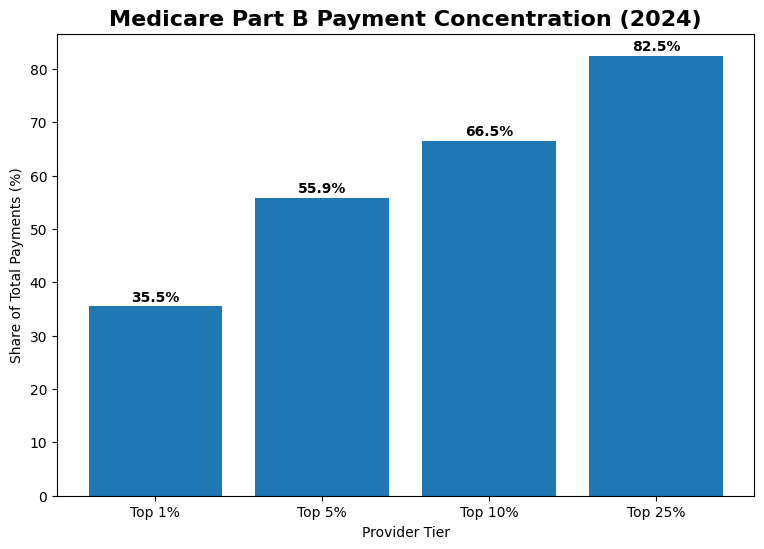

In [136]:
# 1. Sort payments from highest to lowest
payments = analysis_df["Tot_Mdcr_Pymt_Amt"].sort_values(ascending=False)
total_dollars = payments.sum()

# 2. Calculate the top groups manually
top_1 = payments.head(int(len(payments) * 0.01)).sum() / total_dollars * 100
top_5 = payments.head(int(len(payments) * 0.05)).sum() / total_dollars * 100
top_10 = payments.head(int(len(payments) * 0.10)).sum() / total_dollars * 100
top_25 = payments.head(int(len(payments) * 0.25)).sum() / total_dollars * 100

groups = ["Top 1%", "Top 5%", "Top 10%", "Top 25%"]
shares = [top_1, top_5, top_10, top_25]

# 3. Plot the chart
plt.figure(figsize=(9, 6))
plt.bar(groups, shares)

plt.title("Medicare Part B Payment Concentration (2024)", fontsize=16, weight="bold")
plt.xlabel("Provider Tier")
plt.ylabel("Share of Total Payments (%)")

# Put the numbers on top of the bars
for i in range(len(groups)):
    plt.text(i, shares[i] + 1, f"{shares[i]:.1f}%", ha="center", weight="bold")


plt.show()

Finding: Medicare spending is heavily concentrated, with just the top 10% of practitioners receiving over two-thirds (66.5%) of all Part B payments. However, this high spending doesn't automatically indicate fraud, as it often simply reflects large clinics, hospitals, or specialties that use expensive treatments like oncology infusions.

### **Question 2: Do OIG-matched providers bill a significantly higher volume of services per beneficiary than non-excluded providers after accounting for overall total number of unique individual patients (patient panel size).**

 ⁠Hypothesis: Our hypothesis is that patient panel size and total service volume will show a strong positive linear relationship, confirming that providers serving more patients naturally deliver more services.

 Why it matters: This matters because reviewers need a normal baseline for practice size. If auditors ignore how many patients a clinic sees, they risk creating false positives by flagging large clinics simply because they bill for a high number of services.



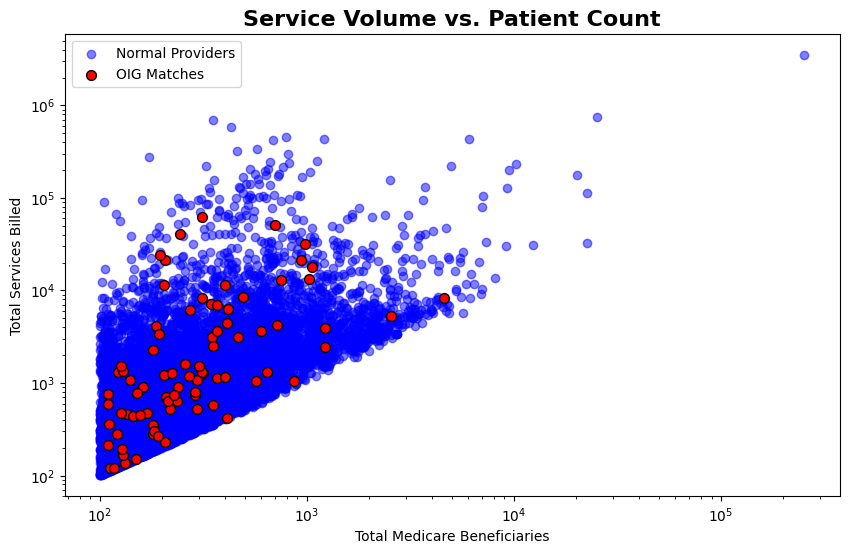

In [ ]:
# 1. Filter out low beneficiary providers
df_chart2 = analysis_df[analysis_df["Tot_Benes"] >= 100]

# 2. Split into normal providers and fraud matches
normal_providers = df_chart2[df_chart2["oig_matched"] == False]
fraud_matches = df_chart2[df_chart2["oig_matched"] == True]

# Sample normal providers so the chart doesn't crash your browser
normal_sample = normal_providers.sample(n=10000, random_state=42)

# 3. Plot the chart
plt.figure(figsize=(10, 6))
plt.scatter(normal_sample["Tot_Benes"], normal_sample["Tot_Srvcs"], color="blue", alpha=0.5, label="Normal Providers")
plt.scatter(fraud_matches["Tot_Benes"], fraud_matches["Tot_Srvcs"], color="red", s=50, edgecolor="black", label="OIG Matches")
plt.xscale("log")
plt.yscale("log")

plt.title("Service Volume vs. Patient Count", fontsize=16, weight="bold")
plt.xlabel("Total Medicare Beneficiaries")
plt.ylabel("Total Services Billed")
plt.legend()
plt.show()

Finding: Beneficiary volume and service volume show a strong positive linear relationship. This suggests that total services predictably grow as a provider's patient count increases. Because of this, high raw service counts essentially indicate a larger clinic rather than being an abnormal billing behavior.

### **Question 3: How does median Medicare payment per service differ across provider specialties?**

Hypothesis: We expect payment per service to vary across specialties because providers in different specialties deliver different types of services with different costs and payment levels.

Why It Matters: Comparing payments across all providers without considering specialty may lead to misleading conclusions. Understanding these differences can help the CMS Program Integrity Team establish more appropriate peer groups when reviewing unusual billing patterns.


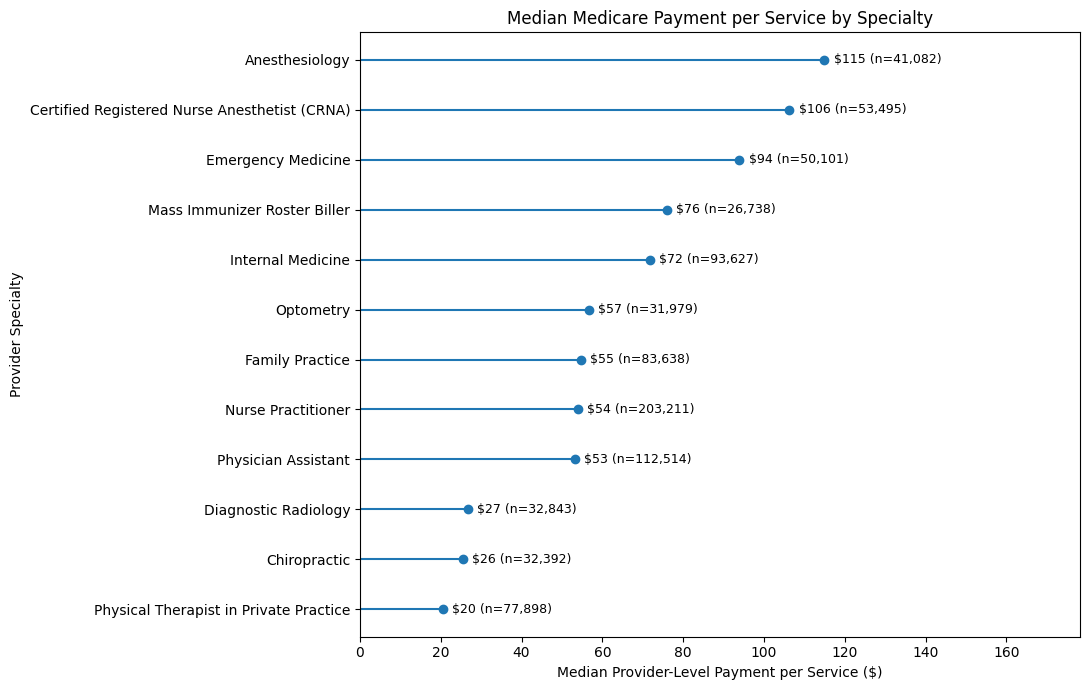

Non-positive payment records excluded: 8


,median_payment,provider_count
Rndrng_Prvdr_Type,,
Physical Therapist in Private Practice,20.497663,77898
Chiropractic,25.550153,32392
Diagnostic Radiology,26.653599,32843
Physician Assistant,53.181129,112514
Nurse Practitioner,53.965397,203211
Family Practice,54.714768,83638
Optometry,56.733333,31979
Internal Medicine,71.755790,93627
Mass Immunizer Roster Biller,76.009618,26738


In [ ]:
# Chart 3: Median Payment per Service by Specialty

cols = ["Rndrng_NPI", "Rndrng_Prvdr_Type", "payment_per_service"]

# Keep providers with valid, positive payment values
chart3 = analysis_df.dropna(subset=cols).copy()
excluded = (chart3["payment_per_service"] <= 0).sum()
chart3 = chart3[chart3["payment_per_service"] > 0].copy()

# Select the 12 specialties with the most providers
top12 = chart3["Rndrng_Prvdr_Type"].value_counts().head(12).index
chart3 = chart3[chart3["Rndrng_Prvdr_Type"].isin(top12)].copy()

# Median payment and provider count by specialty
summary3 = (
    chart3.groupby("Rndrng_Prvdr_Type").agg(median_payment=("payment_per_service", "median"),
        provider_count=("Rndrng_NPI", "nunique"),).sort_values("median_payment"))

# Horizontal dot plot
x = summary3["median_payment"]
y = np.arange(len(summary3))
offset = x.max() * 0.02

fig, ax = plt.subplots(figsize=(11, 7))
ax.hlines(y, 0, x)
ax.scatter(x, y)

# Label each dot with median value and sample size
for yi, payment, n in zip(y, x, summary3["provider_count"]):
    ax.text(payment + offset, yi,f"${payment:,.0f} (n={n:,})",va="center",fontsize=9)

ax.set(yticks=y, yticklabels=summary3.index, xlim=(0, x.max() * 1.55),
    xlabel="Median Provider-Level Payment per Service ($)", ylabel="Provider Specialty",)

ax.set_title("Median Medicare Payment per Service by Specialty")

plt.tight_layout()
plt.show()

print("Non-positive payment records excluded:", excluded)
display(summary3)


Finding: Median payment per service varied across specialties. Anesthesiology had the highest median at $114, while physical therapists in private practice had the lowest at $20.5. This gap shows why a high payment amount should not automatically be treated as unusual: providers in different specialties may deliver services with very different costs. CMS should compare providers with others in the same or similar specialties when deciding which billing patterns deserve a closer look.


### **Question 4: Among Nurse Practitioners, how does median Medicare payment per beneficiary vary across provider groups with different average beneficiary ages?**


Hypothesis: We expect payment per beneficiary to differ across age groups because providers serving older patient populations may see different healthcare needs and service use.

Why It Matters: Differences in patient populations may help explain differences in provider payments. Considering average beneficiary age can give CMS useful context when reviewing unusually high spending.


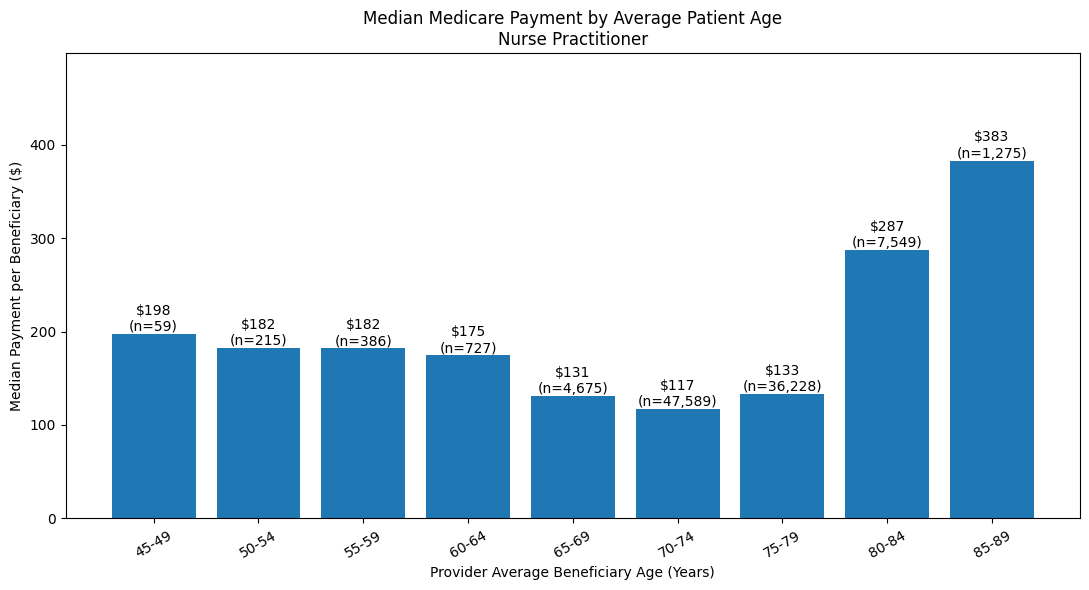

Selected provider type: Nurse Practitioner
Eligible providers: 98720
Age bands excluded (<30 providers): 2


,median_payment,provider_count,age_band
age_start,,,
45,197.513667,59,45-49
50,182.437524,215,50-54
55,181.988056,386,55-59
60,174.584495,727,60-64
65,130.870103,4675,65-69
70,117.396638,47589,70-74
75,133.061795,36228,75-79
80,286.967653,7549,80-84
85,382.928769,1275,85-89


In [ ]:
# Group providers by their average patient age (5-year bands)
# Chart 4: Average Beneficiary Age vs. Medicare Spending

cols = ["Rndrng_NPI","Rndrng_Prvdr_Type","Bene_Avg_Age","Tot_Benes","payment_per_beneficiary",]

# Keep providers with at least 100 beneficiaries and valid values
chart4 = analysis_df.dropna(subset=cols)
chart4 = chart4[(chart4["Tot_Benes"] >= 100) & chart4["Bene_Avg_Age"].between(0, 110, inclusive="right")
    & (chart4["payment_per_beneficiary"] >= 0)]

# Focus on the largest eligible provider type
specialty = chart4["Rndrng_Prvdr_Type"].value_counts().idxmax()
chart4 = chart4[chart4["Rndrng_Prvdr_Type"] == specialty].copy()
chart4["age_start"] = (chart4["Bene_Avg_Age"] // 5 * 5).astype(int)


# Median payment and provider count for each age band
summary4 = (chart4.groupby("age_start").agg(median_payment=("payment_per_beneficiary", "median"),
        provider_count=("Rndrng_NPI", "nunique"),).sort_index())

# Exclude age bands with fewer than 30 providers
small_band = summary4["provider_count"] < 30
excluded_bands = small_band.sum()

summary4 = summary4[~small_band].copy()
summary4["age_band"] = [f"{age}-{age + 4}" for age in summary4.index]

# Bar chart
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(summary4["age_band"], summary4["median_payment"])

# Label median payment and provider count
ax.bar_label(bars, labels=[f"${payment_median:,.0f}\n(n={num_provider:,})"
        for payment_median, num_provider in zip(summary4["median_payment"], summary4["provider_count"])])

ax.set(xlabel="Provider Average Beneficiary Age (Years)", ylabel="Median Payment per Beneficiary ($)",
    ylim=(0, summary4["median_payment"].max() * 1.3))

ax.set_title(f"Median Medicare Payment by Average Patient Age\n{specialty}")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print("Selected provider type:", specialty)
print("Eligible providers:", chart4["Rndrng_NPI"].nunique())
print("Age bands excluded (<30 providers):", excluded_bands)

display(summary4)


Finding: Among 98,720 eligible Nurse Practitioners, median Medicare payment per beneficiary varied across groups based on providers' average beneficiary age. One possible reason is that providers serving different patient populations may face different healthcare needs and patterns of service use. This chart suggests that patient age may provide useful context when reviewing payment differences, but it does not show that age itself causes higher spending or account for every difference between providers.


### **Question 5: What does our original payment screen identify?**

Hypothesis: Our hypothesis is that providers flagged for extreme billing (the top 1% in total payments and payments per patient) will barely overlap with confirmed OIG exclusions, proving that gross dollar thresholds fail to catch bad actors.

⁠Why it matters: This matters because screening rules generate the actual workload for audit teams. Testing these basic financial filters against historical exclusions shows us whether dollar screens create good leads or just waste time on false positives.



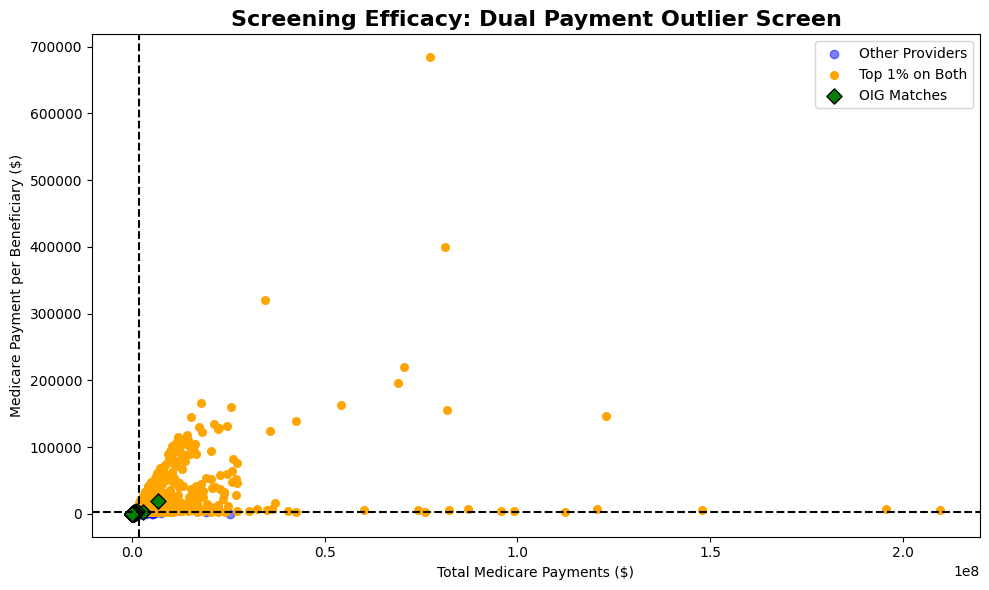

In [ ]:
# 1. Filter data (only providers with 100+ patients)
df_chart5 = analysis_df[analysis_df["Tot_Benes"] >= 100].copy()

# Ensure these columns are numbers
df_chart5["Tot_Mdcr_Pymt_Amt"] = pd.to_numeric(df_chart5["Tot_Mdcr_Pymt_Amt"])
df_chart5["payment_per_beneficiary"] = pd.to_numeric(df_chart5["payment_per_beneficiary"])

# 2. Find the top 1% cutoffs
top_pay = df_chart5["Tot_Mdcr_Pymt_Amt"].quantile(0.99)
top_per_patient = df_chart5["payment_per_beneficiary"].quantile(0.99)

# 3. Split the data into 3 groups: High on Both, OIG Matches, and Everyone Else
high_both = df_chart5[(df_chart5["Tot_Mdcr_Pymt_Amt"] >= top_pay) & (df_chart5["payment_per_beneficiary"] >= top_per_patient)]
fraud = df_chart5[df_chart5["oig_matched"] == True]

# Get the normal providers (not high on both, not fraud) and sample them
normal = df_chart5[(df_chart5["oig_matched"] == False) & ~df_chart5.index.isin(high_both.index)]
normal_sample = normal.sample(n=10000, random_state=42)

# 4. Plot the chart
plt.figure(figsize=(10, 6))
plt.scatter(normal_sample["Tot_Mdcr_Pymt_Amt"], normal_sample["payment_per_beneficiary"], color="blue", alpha=0.5, label="Other Providers")
plt.scatter(high_both["Tot_Mdcr_Pymt_Amt"], high_both["payment_per_beneficiary"], color="orange", s=30, label="Top 1% on Both")
plt.scatter(fraud["Tot_Mdcr_Pymt_Amt"], fraud["payment_per_beneficiary"], color="green", s=60, marker="D", edgecolor="black", label="OIG Matches")

# Draw the dashed cutoff lines
plt.axvline(top_pay, color="black", linestyle="--")
plt.axhline(top_per_patient, color="black", linestyle="--")

plt.title("Screening Efficacy: Dual Payment Outlier Screen", fontsize=16, weight="bold")
plt.xlabel("Total Medicare Payments ($)")
plt.ylabel("Medicare Payment per Beneficiary ($)")
plt.legend()
plt.tight_layout()
plt.show()


Finding: While the 99th-percentile payment screen flags thousands of providers, it misses 82 out of 83 known fraudsters. This proves that extreme dollar outliers are rarely the actual bad actors. Since excluded providers typically bill within normal ranges, we recommend shifting audit strategies away from gross payment thresholds and instead focusing on behavioral indicators, such as unusually high service intensity compared to peers.

### **Question 6: When did the matched providers’ earliest recorded OIG exclusion begin relative to 2024?**



Hypothesis: I expect the earliest exclusion dates to fall before, during, or after 2024.

Why it matters: Comparing exclusion dates with the billing year can help identify providers whose records may need historical verification.

period
Before 2024      1
During 2024     14
After 2024     142
Name: count, dtype: int64


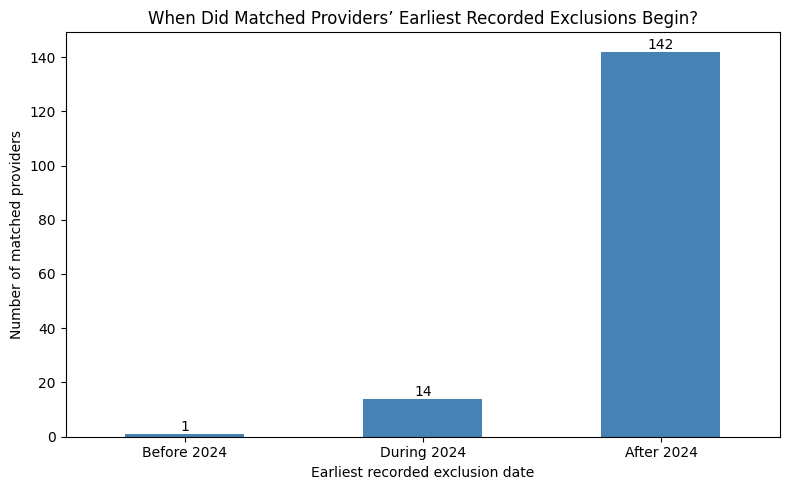

In [ ]:
# Make a working copy of the OIG provider IDs and exclusion dates.
chart6 = oig_data[["NPI", "EXCLDATE"]].copy()

# Clean the OIG provider IDs.
chart6["NPI_clean"] = chart6["NPI"].astype("string").str.strip()

# Make a list of provider IDs from the CMS file.
cms_npi = cms_data[["Rndrng_NPI"]].copy()
cms_npi["NPI_clean"] = cms_npi["Rndrng_NPI"].astype("string").str.strip()
cms_npi = cms_npi[["NPI_clean"]].drop_duplicates()

# Remove blank and placeholder IDs from both files.
chart6 = chart6[chart6["NPI_clean"].notna() & (chart6["NPI_clean"] != "")& (chart6["NPI_clean"] != "0000000000")]
cms_npi = cms_npi[cms_npi["NPI_clean"].notna()& (cms_npi["NPI_clean"] != "") & (cms_npi["NPI_clean"] != "0000000000")]

# Change the OIG exclusion dates into date values.
# Invalid dates, such as 0, will become missing.
chart6["exclusion_date"] = pd.to_datetime(chart6["EXCLDATE"].astype("string").str.replace(r"\.0$", "", regex=True),
    format="%Y%m%d", errors="coerce")

# Keep only providers whose IDs appear in both files.
matched_chart6 = pd.merge(chart6, cms_npi, on="NPI_clean", how="inner")

# Find each matched provider's earliest valid exclusion date.
earliest_dates = (matched_chart6.dropna(subset=["exclusion_date"]).groupby("NPI_clean")["exclusion_date"].min().reset_index())

# Put each provider into a period based on the year of that date.
earliest_dates["period"] = "After 2024"
earliest_dates.loc[earliest_dates["exclusion_date"].dt.year < 2024, "period"] = "Before 2024"
earliest_dates.loc[earliest_dates["exclusion_date"].dt.year == 2024, "period"] = "During 2024"

# Count providers in each period, keeping all three labels on the chart.
period_order = ["Before 2024", "During 2024", "After 2024"]
period_counts = earliest_dates["period"].value_counts().reindex(period_order, fill_value=0)

# Show the counts.
print(period_counts)

# Draw the bar chart.
ax = period_counts.plot(kind="bar", color="steelblue", figsize=(8, 5))
ax.set_title("When Did Matched Providers’ Earliest Recorded Exclusions Begin?")
ax.set_xlabel("Earliest recorded exclusion date")
ax.set_ylabel("Number of matched providers")
ax.tick_params(axis="x", rotation=0)

# Put the count above each bar.
for bar in ax.patches:
    ax.annotate(str(int(bar.get_height())), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom")

plt.tight_layout()
plt.show()

Finding: Of the 157 matched providers with a valid earliest recorded exclusion date, 142 (about 90.4%) had an exclusion that began after 2024, 14 (about 8.9%) had one that began during 2024, and 1 (about 0.6%) had one that began before 2024. This means that 15 providers had an earliest recorded exclusion date on or before the 2024 billing year, while most matches had a later date. The chart compares the dates recorded in the OIG file with the billing year; it does not show when individual services were provided.

### **Question 7: What types of exclusions appear among our OIG matches?**



Hypothesis: The matched providers represent several different exclusion categories.

Why it matters: Exclusions can have different reasons. Knowing the category helps reviewers interpret a match carefully rather than treating every match as evidence of Medicare billing fraud.

category
Disclosure or payment-information requirement        1
Misdemeanor controlled-substance conviction          1
Misdemeanor health-care fraud conviction             2
Patient abuse or neglect conviction                  3
Fraud, kickbacks, or other prohibited activities     4
Felony health-care fraud conviction                  8
Felony controlled-substance conviction              11
Program-related conviction                          45
License revocation, suspension, or surrender        82
Name: count, dtype: int64


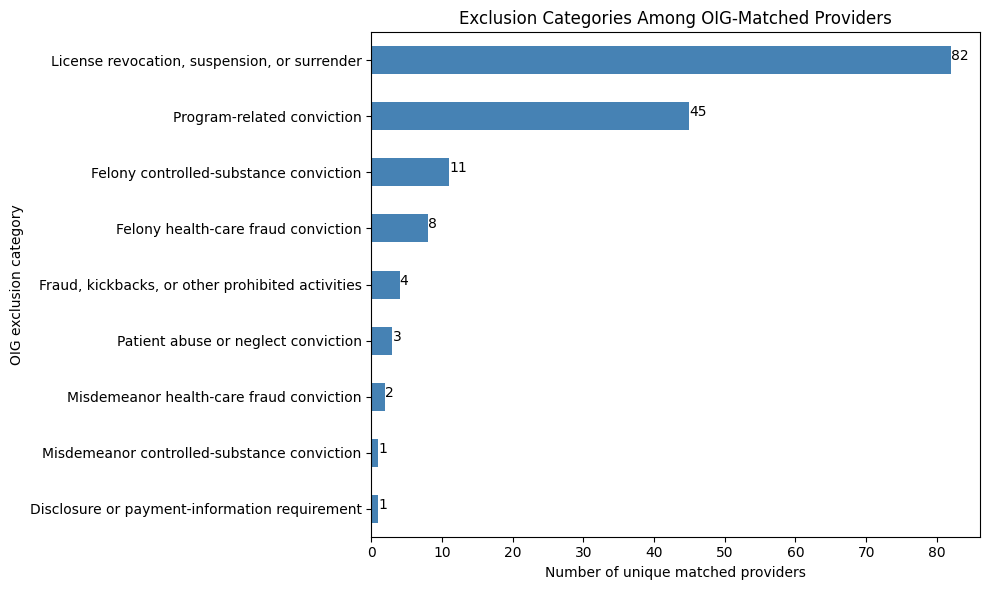

Codes labeled Other:
Series([], Name: count, dtype: int64)


In [ ]:
# Make a working copy of the OIG provider IDs and exclusion categories.
chart7 = oig_data[["NPI", "EXCLTYPE"]].copy()

# Clean the OIG provider IDs.
chart7["NPI_clean"] = chart7["NPI"].astype("string").str.strip()

# Make a list of provider IDs from the CMS file.
cms_npi = cms_data[["Rndrng_NPI"]].copy()
cms_npi["NPI_clean"] = cms_npi["Rndrng_NPI"].astype("string").str.strip()
cms_npi = cms_npi[["NPI_clean"]].drop_duplicates()

# Remove blank and placeholder IDs from both files.
chart7 = chart7[chart7["NPI_clean"].notna() & (chart7["NPI_clean"] != "") & (chart7["NPI_clean"] != "0000000000")]
cms_npi = cms_npi[cms_npi["NPI_clean"].notna() & (cms_npi["NPI_clean"] != "") & (cms_npi["NPI_clean"] != "0000000000")]

# Keep only providers whose IDs appear in both files.
matched_chart7 = pd.merge(chart7, cms_npi, on="NPI_clean", how="inner")

# Make the exclusion codes consistent for matching to their descriptions.
matched_chart7["code"] = (matched_chart7["EXCLTYPE"].astype("string").str.lower().str.replace(r"[^a-z0-9]", "", regex=True))

# Translate the OIG codes into readable descriptions.
category_names = {
    "1128a1": "Program-related conviction",
    "1128a2": "Patient abuse or neglect conviction",
    "1128a3": "Felony health-care fraud conviction",
    "1128a4": "Felony controlled-substance conviction",
    "1128b1": "Misdemeanor health-care fraud conviction",
    "1128b3": "Misdemeanor controlled-substance conviction",
    "1128b4": "License revocation, suspension, or surrender",
    "1128b7": "Fraud, kickbacks, or other prohibited activities",
    "1128b9": "Disclosure or payment-information requirement",
    "1128b10": "Disclosure or payment-information requirement",
    "1128b11": "Disclosure or payment-information requirement"
}

# Give each code its description; show any unlisted code as "Other."
matched_chart7["category"] = matched_chart7["code"].map(category_names)
matched_chart7["category"] = matched_chart7["category"].fillna("Other")

# Count each provider once within each category.
# A provider can be counted in more than one category if they have multiple codes.
matched_chart7 = matched_chart7.drop_duplicates(subset=["NPI_clean", "category"])
category_counts = matched_chart7["category"].value_counts().sort_values()

# Show the counts.
print(category_counts)

# Draw the horizontal bar chart.
ax = category_counts.plot(kind="barh", color="steelblue", figsize=(10, 6))
ax.set_title("Exclusion Categories Among OIG-Matched Providers")
ax.set_xlabel("Number of unique matched providers")
ax.set_ylabel("OIG exclusion category")

# Put the count at the end of each bar.
for bar in ax.patches:
    ax.annotate(str(int(bar.get_width())), (bar.get_width(), bar.get_y() + bar.get_height() / 2))


plt.tight_layout()
plt.show()

# Check whether any codes need a description added.
print("Codes labeled Other:")
print(matched_chart7.loc[matched_chart7["category"] == "Other", "EXCLTYPE"].value_counts())

Finding: The largest category was license revocation, suspension, or surrender, with 82 matched providers. Program-related conviction was next, with 45. The other categories were felony controlled-substance conviction (11), felony health-care fraud conviction (8), fraud or kickbacks (4), patient abuse or neglect (3), misdemeanor health-care fraud conviction (2), misdemeanor controlled-substance conviction (1), and a disclosure or payment-information requirement (1).

### **Question 8: Do matched providers deliver more services per patient?**

Hypothesis: We expect OIG-matched providers to have higher median service intensity than other providers, meaning more services per beneficiary.

Why It Matters: Variety of service intensities may reveal billing patterns that payment amounts miss. Services per beneficiary can give CMS another signal when reviewing providers, to find cases that a payment screen would overlook.

Other providers median: 2.87
OIG-matched providers median: 4.07
Difference: 41.5 %


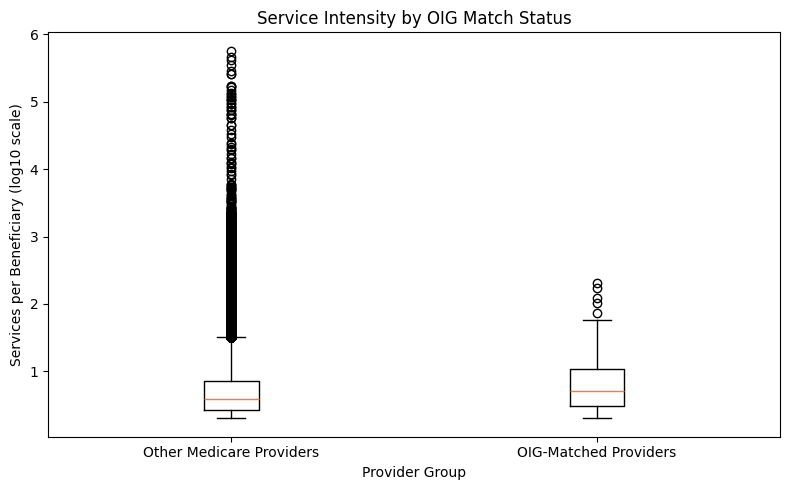

In [ ]:
service_summary = (analysis_df.groupby("oig_matched")["services_per_beneficiary"].agg(["count", "median", "mean"]))
service_summary.index = ["Other Medicare Providers","OIG-Matched Providers"]

non_oig_median = service_summary.loc["Other Medicare Providers","median"]
oig_median = service_summary.loc["OIG-Matched Providers","median"]

service_difference_pct = ((oig_median - non_oig_median) / non_oig_median * 100)

print("Other providers median:", round(non_oig_median, 2))
print("OIG-matched providers median:",round(oig_median, 2))
print("Difference:",round(service_difference_pct, 1),"%")

non_oig_services = np.log10(analysis_df.loc[~analysis_df["oig_matched"],"services_per_beneficiary"] + 1)
oig_services = np.log10(analysis_df.loc[analysis_df["oig_matched"],"services_per_beneficiary"] + 1)

plt.figure(figsize=(8, 5))
plt.boxplot([non_oig_services.dropna(),oig_services.dropna()],
    tick_labels=["Other Medicare Providers","OIG-Matched Providers"], showfliers=True)

plt.title("Service Intensity by OIG Match Status")
plt.xlabel("Provider Group")
plt.ylabel("Services per Beneficiary (log10 scale)")
plt.tight_layout()
plt.show()

# Log scale used as raw numbers make the plot impossible to interpret visually

Findings: The box for OIG-matched providers sits slightly higher than the box for other providers, showing that a typical matched provider bills more services per patient. However, the two boxes overlap heavily, so most matched providers fall within the same range as everyone else. The most extreme values belong to other providers, whose outliers stretch far above the highest values among matched providers.

### **Question 9: Does billing-code diversity differ between OIG-matched and other providers?**

Hypothesis: We expect OIG-matched providers to differ in code diversity, such as billing unusually narrow or unusually broad sets of procedure codes.

Why It Matters: Code diversity is a billing characteristic that payment amounts and service counts do not capture. If it differs between groups, it could give reviewers another way to detect unusual billing patterns.

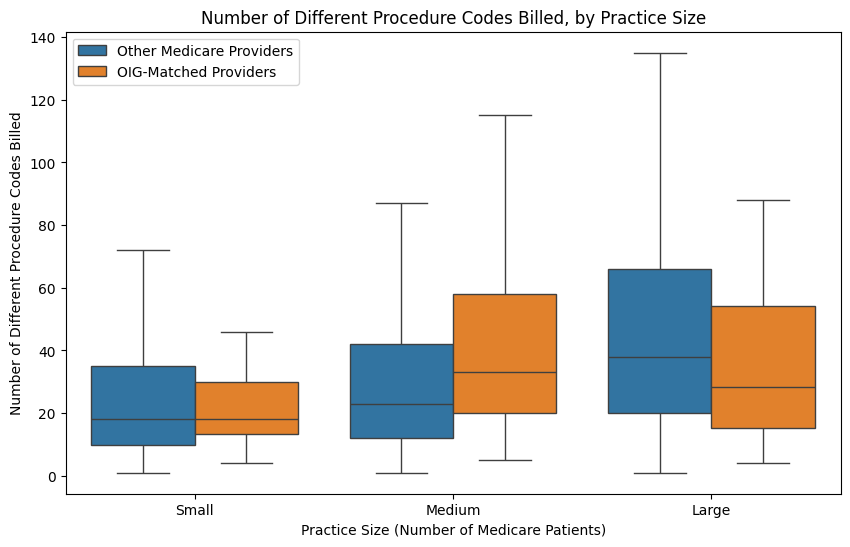

,min,max,count
size_group,,,
Small,100,183,254175
Medium,184,346,250472
Large,347,1560327,251246


group,OIG-Matched Providers,Other Medicare Providers
size_group,,
Small,26,254149
Medium,29,250443
Large,28,251218


size_group  group                   
Small       OIG-Matched Providers       18.0
            Other Medicare Providers    18.0
Medium      OIG-Matched Providers       33.0
            Other Medicare Providers    23.0
Large       OIG-Matched Providers       28.5
            Other Medicare Providers    38.0
Name: Tot_HCPCS_Cds, dtype: float64

In [ ]:
# Only including the providers with 100+ beneficiaries and at least 1 code
chart_9 = payment_bene_df[
    payment_bene_df["Tot_HCPCS_Cds"] > 0
].copy()
chart_9["group"] = np.where(chart_9["oig_matched"], "OIG-Matched Providers", "Other Medicare Providers")

# Split providers into three equal-sized groups by number of beneficiaries
chart_9["size_group"] = pd.qcut(chart_9["Tot_Benes"], q=3, labels=["Small", "Medium", "Large"])

# Create side-by-side boxplots: one pair per size group(Small,Medium,Large)
plt.figure(figsize=(10, 6))
sns.boxplot(data=chart_9, x="size_group", y="Tot_HCPCS_Cds", hue="group",
            hue_order=["Other Medicare Providers", "OIG-Matched Providers"], showfliers=False)
plt.title("Number of Different Procedure Codes Billed, by Practice Size")
plt.xlabel("Practice Size (Number of Medicare Patients)")
plt.ylabel("Number of Different Procedure Codes Billed")
plt.legend(title="")
plt.show()

# Group sizes and median code counts
display(chart_9.groupby("size_group", observed=True)["Tot_Benes"].agg(["min", "max", "count"]))
display(pd.crosstab(chart_9["size_group"], chart_9["group"]))
display(chart_9.groupby(["size_group", "group"], observed=True)["Tot_HCPCS_Cds"].median())

Findings: The pattern changes across practice sizes. In small practices, the two groups look very similar. In medium practices, OIG-matched providers bill a wider range of procedure codes than other providers, while in large practices they bill fewer. In both the small and large groups, the boxes for matched providers are shorter, meaning their code counts are more concentrated in the middle rather than at either extreme. In conlusion, the code diversity doesn't show a consistent difference between the two groups.

### **Question 10: Within broad patient-risk groups, do OIG-matched providers have different median services per beneficiary than other providers?**



Hypothesis: I expect the difference in service intensity to vary across patient-risk groups. Some differences may remain after comparing providers whose patients have similar average risk.

Why it matters: Patients with greater health needs may require more services. Comparing providers within similar risk groups helps reviewers consider patient complexity when looking at differences in service intensity.

,risk_band,provider_group,median_services,provider_count
0,Higher risk,OIG-matched providers,6.455326,26
1,Higher risk,Other providers,2.448276,251933
2,Lower risk,OIG-matched providers,3.451852,13
3,Lower risk,Other providers,3.444737,251989
4,Middle risk,OIG-matched providers,4.756128,44
5,Middle risk,Other providers,2.775862,251888


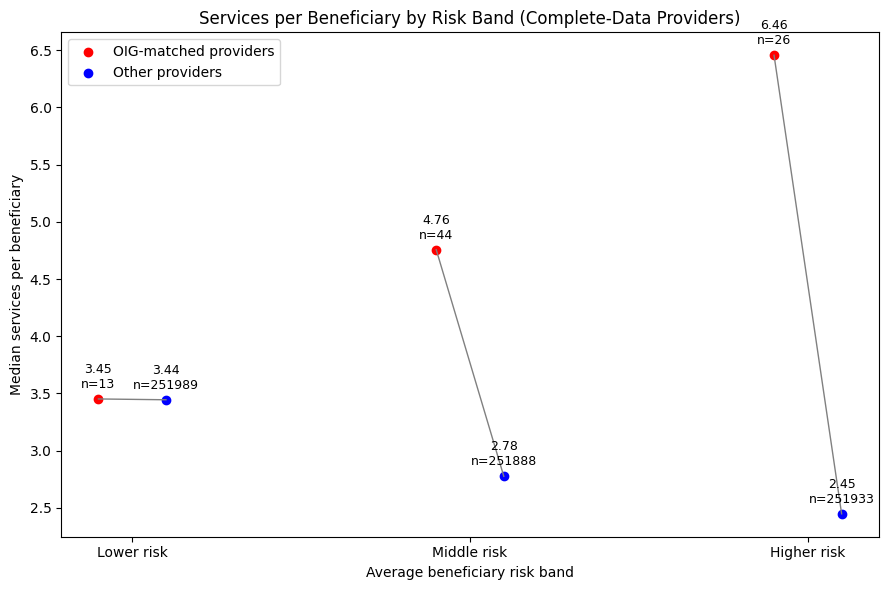

In [ ]:
# Get the provider IDs that matched between the OIG and CMS files.
matched_npis = set(matched_chart7["NPI_clean"])

# Make a working copy with the columns needed for Chart 10.
chart10 = cms_data[["Rndrng_NPI", "Tot_Benes", "Tot_Srvcs", "Bene_Avg_Risk_Scre"]].copy()

# Convert these columns to numbers.
chart10["Tot_Benes"] = pd.to_numeric(chart10["Tot_Benes"], errors="coerce")
chart10["Tot_Srvcs"] = pd.to_numeric(chart10["Tot_Srvcs"], errors="coerce")
chart10["Bene_Avg_Risk_Scre"] = pd.to_numeric(chart10["Bene_Avg_Risk_Scre"], errors="coerce")

# Remove rows missing a value needed for the chart.
chart10 = chart10.dropna(subset=["Rndrng_NPI", "Tot_Benes", "Tot_Srvcs", "Bene_Avg_Risk_Scre"])

# Remove providers less than 100 beneficiaries.
chart10 = chart10[chart10["Tot_Benes"] >= 100].copy()

# Calculate each provider's services per beneficiary.
chart10["services_per_beneficiary"] = (chart10["Tot_Srvcs"] / chart10["Tot_Benes"])

# Divide providers into lower, middle, and higher risk bands.
low_cutoff = chart10["Bene_Avg_Risk_Scre"].quantile(1 / 3)
middle_cutoff = chart10["Bene_Avg_Risk_Scre"].quantile(2 / 3)

chart10["risk_band"] = "Higher risk"
chart10.loc[chart10["Bene_Avg_Risk_Scre"] <= middle_cutoff, "risk_band"] = "Middle risk"
chart10.loc[chart10["Bene_Avg_Risk_Scre"] <= low_cutoff, "risk_band"] = "Lower risk"

# Label providers as OIG-matched or other.
chart10["NPI_clean"] = chart10["Rndrng_NPI"].astype("string").str.strip()
chart10["provider_group"] = "Other providers"
chart10.loc[chart10["NPI_clean"].isin(matched_npis), "provider_group"] = "OIG-matched providers"

# Calculate the median and number of providers in each group.
summary = chart10.groupby(["risk_band", "provider_group"]).agg(median_services=("services_per_beneficiary", "median"),
    provider_count=("NPI_clean", "nunique")).reset_index()

# Display the medians and counts used in the chart.
display(summary)

# Set the order of the risk bands and provider groups.
risk_bands = ["Lower risk", "Middle risk", "Higher risk"]
groups = ["OIG-matched providers", "Other providers"]
colors = ["red", "blue"]
offsets = [-0.1, 0.1]

plt.figure(figsize=(9, 6))

# Draw a gray line between the two group medians in each risk band.
for i, risk in enumerate(risk_bands):
    matched_row = summary[(summary["risk_band"] == risk) & (summary["provider_group"] == "OIG-matched providers")]
    other_row = summary[(summary["risk_band"] == risk) & (summary["provider_group"] == "Other providers")]

    if len(matched_row) > 0 and len(other_row) > 0:
        matched_median = matched_row["median_services"].iloc[0]
        other_median = other_row["median_services"].iloc[0]

        plt.plot([i + offsets[0], i + offsets[1]],[matched_median, other_median], color="gray",linewidth=1)

# Draw and label the dots.
for i, risk in enumerate(risk_bands):
    for j, group in enumerate(groups):
        result = summary[(summary["risk_band"] == risk) & (summary["provider_group"] == group)]

        if len(result) > 0:
            median = result["median_services"].iloc[0]
            count = result["provider_count"].iloc[0]
            x = i + offsets[j]

            plt.scatter(x, median,color=colors[j],label=group if i == 0 else "")

            # Show the median and provider count beside each dot.
            plt.annotate(f"{median:.2f}\nn={count}",(x, median),xytext=(0, 8),textcoords="offset points",
                ha="center", fontsize=9)

# Add the chart title and axis labels.
plt.xticks([0, 1, 2], risk_bands)
plt.xlabel("Average beneficiary risk band")
plt.ylabel("Median services per beneficiary")
plt.title("Services per Beneficiary by Risk Band (Complete-Data Providers)")
plt.legend()
plt.tight_layout()
plt.show()

**Finding:** The matched-provider median was slightly higher in the lower-risk band and much higher in the middle- and higher-risk bands:

*   Lower risk:** 3.45 services per beneficiary for matched providers (13 providers), compared with 3.44 for other providers (251,989 providers).
*   Middle risk: 4.76 for matched providers (44 providers), compared with 2.78 for other providers (251,888 providers).
*   Higher risk:** 6.46 for matched providers (26 providers), compared with 2.45 for other providers (251,933 providers).

A reviewer could treat these differences as screening signals, compare providers with similar specialties and patient profiles, and examine service-level billing. This chart includes 83 matched providers after the beneficiary minimum and complete-data filters; the small lower- and higher-risk matched groups and the broad risk bands limit how strongly we can interpret the differences. The takeaway is that the matched-provider median was higher in each risk band, especially in the middle and higher bands, but the chart does not prove improper billing.

### **Question 11: Who bills unusually often compared with their own specialty?**



Hypothesis: Some providers have unusually high service intensity within their specialty despite falling below national payment thresholds.

Why it matters: Specialties provide different types and volumes of services. Comparing providers within their specialty gives reviewers a more relevant starting point for identifying unusual billing intensity.


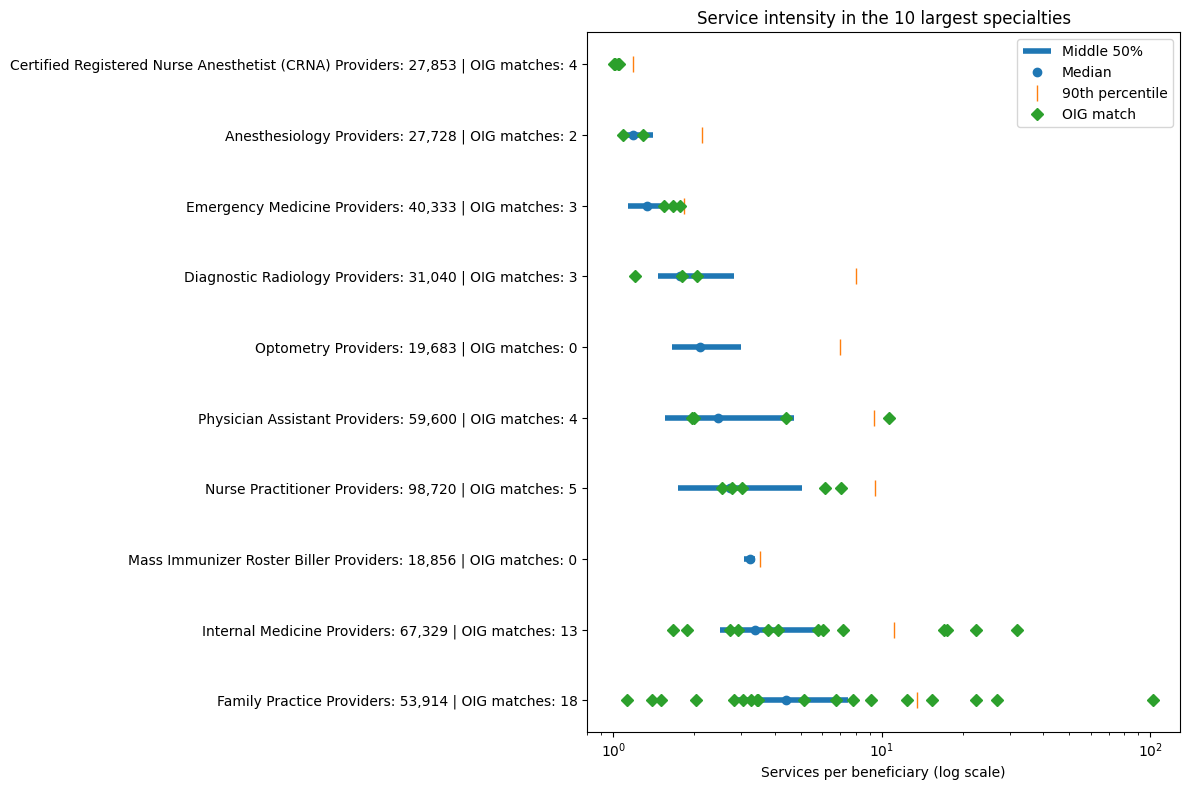

In [ ]:
# Chart 11: Service intensity in the 10 largest specialties
chart11 = analysis_df.rename(columns={"Rndrng_Prvdr_Type": "specialty", "Tot_Benes": "beneficiaries",
    "Tot_Mdcr_Pymt_Amt": "total_payment"}).copy()

# Keep eligible providers.
chart11 = chart11[chart11["beneficiaries"] >= 100].copy()
chart11 = chart11[chart11["services_per_beneficiary"] > 0].copy()
chart11 = chart11[chart11["total_payment"] >= 0].copy()
chart11 = chart11.dropna(subset=["specialty"])
chart11 = chart11[chart11["specialty"] != ""].copy()

# Count providers in each specialty, from largest to smallest.
specialty_counts11 = chart11["specialty"].value_counts()
specialty_counts11 = specialty_counts11[specialty_counts11 >= 100]

# Select the 10 largest eligible specialties.
largest_specialties11 = specialty_counts11.head(10).index

# Calculate statistics for each selected specialty.
summary_rows11 = []

for specialty11 in largest_specialties11:
    specialty_data11 = chart11[chart11["specialty"] == specialty11]
    services11 = specialty_data11["services_per_beneficiary"]
    oig_count11 = int(specialty_data11["oig_matched"].sum())

    # Each dictionary becomes one row in the summary table.
    summary_rows11.append({
        "specialty": specialty11,
        "provider_count": len(specialty_data11),
        "lower_quartile": services11.quantile(0.25),
        "median_services": services11.median(),
        "upper_quartile": services11.quantile(0.75),
        "percentile_90": services11.quantile(0.90),
        "oig_matches": oig_count11
    })

summary11 = pd.DataFrame(summary_rows11)

# Arrange specialties by median service intensity.
summary11 = summary11.sort_values("median_services")
summary11 = summary11.reset_index(drop=True)

# Prepare specialty labels and OIG points.
specialty_labels11 = []
oig_services11 = []
oig_rows11 = []

for row11 in summary11.index:
    specialty11 = summary11.loc[row11, "specialty"]
    provider_count11 = int(summary11.loc[row11, "provider_count"])
    oig_count11 = int(summary11.loc[row11, "oig_matches"])

    specialty_label11 = (f"{specialty11} Providers: {provider_count11:,} | OIG matches: {oig_count11}")
    specialty_labels11.append(specialty_label11)

    # Find OIG-matched providers in this specialty.
    specialty_data11 = chart11[chart11["specialty"] == specialty11]
    oig_providers11 = specialty_data11[specialty_data11["oig_matched"]]

    # Record each OIG provider's intensity and chart row.
    for service_count11 in oig_providers11["services_per_beneficiary"]:
        oig_services11.append(service_count11)
        oig_rows11.append(row11)

# Create the chart.
plt.figure(figsize=(12, 8))

plt.hlines(summary11.index,summary11["lower_quartile"],summary11["upper_quartile"],linewidth=4,label="Middle 50%")
plt.plot(summary11["median_services"],summary11.index,"o",label="Median")
plt.plot(summary11["percentile_90"],summary11.index,"|",markersize=12,label="90th percentile")
plt.plot(oig_services11, oig_rows11,"D",label="OIG match")

plt.yticks(summary11.index, specialty_labels11)
plt.gca().invert_yaxis()
plt.xscale("log")

plt.xlabel("Services per beneficiary (log scale)")
plt.title("Service intensity in the 10 largest specialties")
plt.legend()
plt.tight_layout()
plt.show()

# Only this display is limited to the 10 largest eligible specialties.

Finding: Median service intensity varies across specialties, with Family Practice having the highest median and Certified Registered Nurse Anesthetists having the lowest among the 10 specialities displayed here. Some OIG matched providers in Family Practice, Internal Medicine, and Physician Assistant exceed their specialty’s 90th-percentile threshold, while many others fall below it. Moving forward, we could compare intensity within specialty and use unusually high intensity as a starting point for investigation.

### **Question 12: Do specialty-relative high payment and high service intensity screens identify the same providers?**


Hypothesis: We expect the screens to identify some of the same providers, but also different providers, because high spending per beneficiary and high service volume per beneficiary capture different billing patterns.

Why It Matters: A payment only screen may miss providers with unusually frequent services, while a service intensity only screen may miss providers with unusually high payments. Comparing both signals can help CMS decide which providers may warrant closer review.


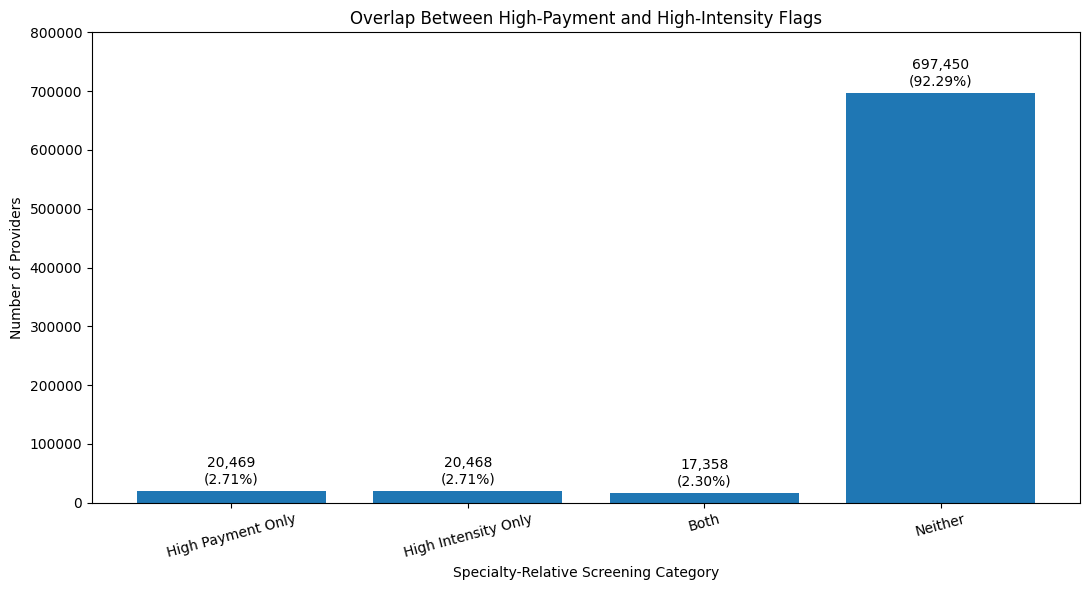

Eligible providers: 755745
Specialties included: 93
Threshold: 95th percentile within each specialty


,Provider Count,Percentage (%)
flag_category,,
High Payment Only,20469,2.71
High Intensity Only,20468,2.71
Both,17358,2.30
Neither,697450,92.29


Overlap among flagged providers: 29.8%


In [ ]:
# Chart 12: Overlap Between High-Payment and High-Intensity Flags
threshold12 = 0.95
columns12 = ["Rndrng_NPI", "Rndrng_Prvdr_Type","payment_per_beneficiary","services_per_beneficiary"]

# payment_bene_df already contains providers with at least 100 beneficiaries.
chart12 = payment_bene_df.dropna(subset=columns12).copy()
chart12 = chart12[chart12["payment_per_beneficiary"] >= 0]
chart12 = chart12[chart12["services_per_beneficiary"] > 0]

# Keep specialties with at least 30 eligible providers.
specialty_counts12 = chart12["Rndrng_Prvdr_Type"].value_counts()
large_specialties12 = specialty_counts12[specialty_counts12 >= 30].index

chart12 = chart12[chart12["Rndrng_Prvdr_Type"].isin(large_specialties12)].copy()

# Calculate each specialty's 95th-percentile thresholds.
payment_thresholds12 = chart12.groupby("Rndrng_Prvdr_Type")["payment_per_beneficiary"].quantile(threshold12)
intensity_thresholds12 = chart12.groupby("Rndrng_Prvdr_Type")["services_per_beneficiary"].quantile(threshold12)

# Give each provider the thresholds for their specialty.
chart12["payment_threshold"] = chart12["Rndrng_Prvdr_Type"].map(payment_thresholds12)
chart12["intensity_threshold"] = chart12["Rndrng_Prvdr_Type"].map(intensity_thresholds12)

# Identify providers above each threshold.
high_payment12 = (chart12["payment_per_beneficiary"] > chart12["payment_threshold"])
high_intensity12 = (chart12["services_per_beneficiary"] > chart12["intensity_threshold"])

# Assign categories. "Both" comes last to replace either single-flag label.
chart12["flag_category"] = "Neither"
chart12.loc[high_payment12, "flag_category"] = "High Payment Only"
chart12.loc[high_intensity12, "flag_category"] = "High Intensity Only"
chart12.loc[high_payment12 & high_intensity12, "flag_category"] = "Both"

# Count providers and calculate percentages.
order12 = ["High Payment Only", "High Intensity Only", "Both", "Neither"]

summary12 = chart12["flag_category"].value_counts()
summary12 = summary12.reindex(order12, fill_value=0)
summary12_percent = summary12 / len(chart12) * 100

# Create the labels for the bars.
bar_labels12 = []

for category in order12:
    provider_count = summary12[category]
    percentage = summary12_percent[category]
    bar_labels12.append(f"{provider_count:,}\n({percentage:.2f}%)")

# Create the chart.
plt.figure(figsize=(11, 6))

bars = plt.bar(order12, summary12)
plt.bar_label(bars, labels=bar_labels12, padding=3)


plt.xlabel("Specialty-Relative Screening Category")
plt.ylabel("Number of Providers")
plt.title("Overlap Between High-Payment and High-Intensity Flags")
plt.xticks(rotation=15)


plt.ylim(0, 800000)
plt.tight_layout()
plt.show()

# Display the counts and percentages.
summary_table12 = pd.DataFrame({"Provider Count": summary12,"Percentage (%)": summary12_percent.round(2)})

print("Eligible providers:", len(chart12))
print("Specialties included:", chart12["Rndrng_Prvdr_Type"].nunique())
print(f"Threshold: {threshold12 * 100:g}th percentile within each specialty")

display(summary_table12)

# Among providers with at least one flag, calculate how many have both.
flagged_count12 = len(chart12) - summary12["Neither"]

if flagged_count12 > 0:
    overlap12 = summary12["Both"] / flagged_count12 * 100
    print(f"Overlap among flagged providers: {overlap12:.1f}%")
else:
    print("No providers were flagged.")

Finding: Among 755,745 eligible providers across 93 specialties, 2.71% were flagged only for high payment per beneficiary, 2.71% only for high service intensity, and 2.30% for both; 92.29% were flagged for neither. Among providers flagged by at least one measure, 29.8% were flagged by both. This shows that the two measures overlap, but each also identifies providers the other one misses—so using both can give reviewers a broader picture of billing patterns.

### **Question 13: How do flagged providers’ payments compare with similar peers?**

Hypothesis: Some flagged providers remain substantially above comparable peers, while patient context explains part of others’ spending.

Why it matters: Higher payments may reflect differences in specialty and patient needs. Comparing providers within the same specialty and broad patient-risk band helps identify payment differences that require further explanation.


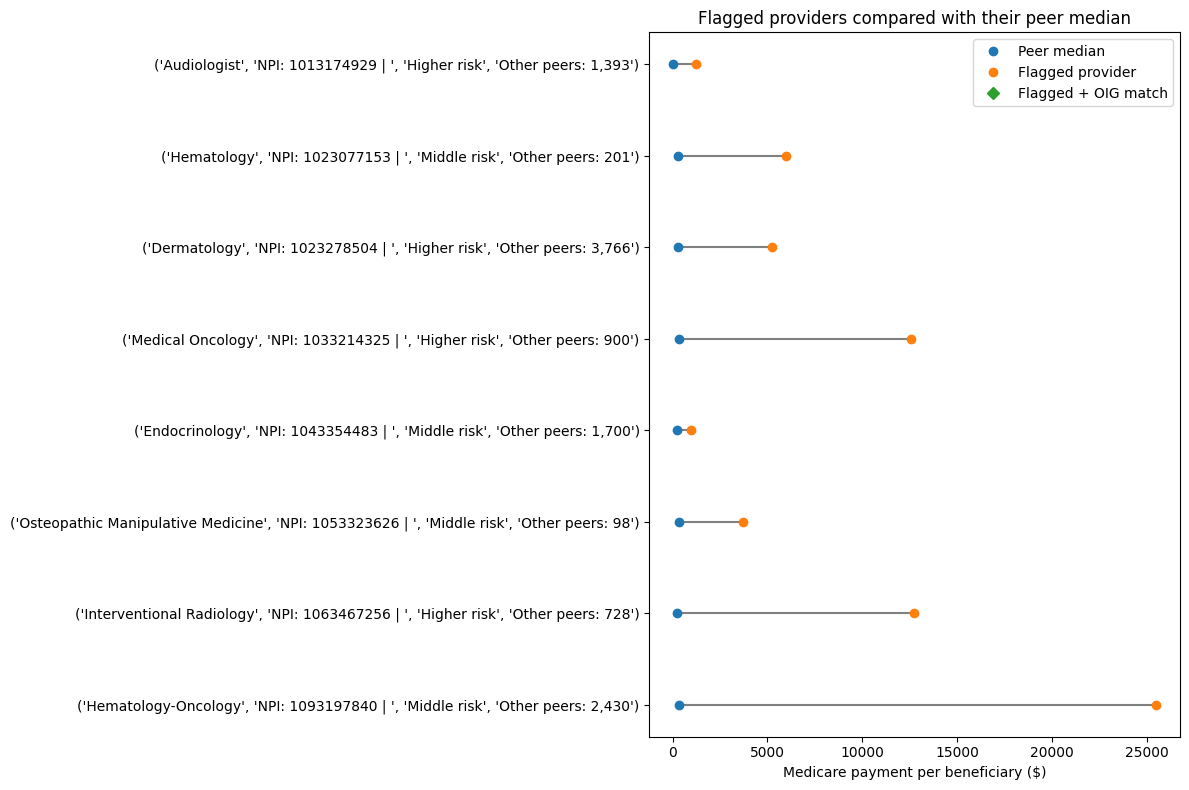

provider_id                         specialty risk_band  peer_count  payment_per_beneficiary  peer_median_payment  oig_matched
 1013174929                       Audiologist    Higher        1393              1205.541462            41.402011        False
 1023077153                        Hematology    Middle         201              5993.602743           268.225984        False
 1023278504                       Dermatology    Higher        3766              5255.462467           284.757375        False
 1033214325                  Medical Oncology    Higher         900             12581.707913           341.061374        False
 1043354483                     Endocrinology    Middle        1700               963.601888           221.200039        False
 1053323626 Osteopathic Manipulative Medicine    Middle          98              3705.706923           312.312458        False
 1063467256          Interventional Radiology    Higher         728             12732.024645           216.3549

In [ ]:
# Chart 13: Flagged providers compared with their peer median
chart13 = analysis_df.rename(columns={"Rndrng_NPI": "provider_id", "Rndrng_Prvdr_Type": "specialty",
    "Tot_Benes": "beneficiaries", "Tot_Mdcr_Pymt_Amt": "total_payment","Bene_Avg_Risk_Scre": "patient_risk"}).copy()

# Keep eligible providers.
chart13 = chart13[chart13["beneficiaries"] >= 100].copy()
chart13 = chart13[chart13["services_per_beneficiary"] > 0].copy()
chart13 = chart13[chart13["total_payment"] >= 0].copy()
chart13 = chart13.dropna(subset=["specialty"])
chart13 = chart13[chart13["specialty"] != ""].copy()

# Keep specialties with at least 100 eligible providers.
specialty_counts13 = chart13["specialty"].value_counts()
large_specialties13 = specialty_counts13[specialty_counts13 >= 100].index

chart13 = chart13[chart13["specialty"].isin(large_specialties13)].copy()

# Create columns that will be filled for each specialty.
chart13["specialty_flag"] = False
chart13["specialty_percentile"] = 0.0
chart13["risk_band"] = "Higher"

# Work through one specialty at a time.
for specialty13 in large_specialties13:
    specialty_rows13 = chart13["specialty"] == specialty13
    specialty_data13 = chart13[specialty_rows13]

    # Calculate this specialty's service-intensity threshold.
    threshold13 = specialty_data13["services_per_beneficiary"].quantile(0.90)
    chart13.loc[specialty_rows13, "specialty_flag"] = (specialty_data13["services_per_beneficiary"] > threshold13)

    # Calculate each provider's percentile rank within its specialty.
    chart13.loc[specialty_rows13, "specialty_percentile"] = (specialty_data13["services_per_beneficiary"].rank(pct=True))

    # Calculate risk cutoffs using providers with valid risk scores.
    risk_data13 = specialty_data13[specialty_data13["patient_risk"] > 0]
    lower_cutoff13 = risk_data13["patient_risk"].quantile(1 / 3)
    upper_cutoff13 = risk_data13["patient_risk"].quantile(2 / 3)

    # Assign middle and lower risk bands.
    chart13.loc[specialty_rows13 & (chart13["patient_risk"] <= upper_cutoff13),"risk_band"] = "Middle"
    chart13.loc[specialty_rows13 & (chart13["patient_risk"] <= lower_cutoff13),"risk_band"] = "Lower"

# Risk scores are required for the peer comparison.
chart13 = chart13[chart13["patient_risk"] > 0].copy()

# Sort flagged providers by their specialty percentile.
candidates13 = chart13[chart13["specialty_flag"]].copy()

candidates13 = candidates13.sort_values(["specialty_percentile", "provider_id"],ascending=[False, True])
selected_rows13 = []
peer_medians13 = []
peer_counts13 = []
provider_labels13 = []

# Select eight examples with at least 30 other suitable peers.
for provider_index13, provider13 in candidates13.iterrows():
    peers13 = chart13[chart13["specialty"] == provider13["specialty"]]
    peers13 = peers13[peers13["risk_band"] == provider13["risk_band"]]

    # Exclude the provider from its own peer group.
    peers13 = peers13[peers13["provider_id"] != provider13["provider_id"]]

    if len(peers13) >= 30:
        selected_rows13.append(provider_index13)
        peer_counts13.append(len(peers13))
        peer_medians13.append(peers13["payment_per_beneficiary"].median())

        provider_label13 = (f"{provider13['specialty']}", f"NPI: {provider13['provider_id']} | ",
            f"{provider13['risk_band']} risk", f"Other peers: {len(peers13):,}")
        provider_labels13.append(provider_label13)

    # Stop after selecting eight providers.
    if len(selected_rows13) == 8:
        break

# Create the table used for plotting.
summary13 = chart13.loc[selected_rows13].copy()
summary13["peer_count"] = peer_counts13
summary13["peer_median_payment"] = peer_medians13
summary13 = summary13.reset_index(drop=True)
oig_providers13 = summary13[summary13["oig_matched"]]

# Create the chart.
plt.figure(figsize=(12, 8))

plt.hlines(summary13.index, summary13["peer_median_payment"],summary13["payment_per_beneficiary"],color="gray")
plt.plot(summary13["peer_median_payment"],summary13.index,"o",label="Peer median")
plt.plot(summary13["payment_per_beneficiary"],summary13.index,"o",label="Flagged provider")
plt.plot(oig_providers13["payment_per_beneficiary"],oig_providers13.index, "D", label="Flagged + OIG match")

plt.yticks(summary13.index, provider_labels13)
plt.gca().invert_yaxis()

plt.xlabel("Medicare payment per beneficiary ($)")
plt.title("Flagged providers compared with their peer median")
plt.legend()
plt.tight_layout()
plt.show()

# Display the numbers behind the chart.
summary_columns13 = ["provider_id", "specialty","risk_band","peer_count", "payment_per_beneficiary","peer_median_payment","oig_matched"]
print(summary13[summary_columns13].to_string(index=False))

Finding: All eight providers in this chart have payments per beneficiary above their peer median. The Hematology Oncology example receives just over $25000 per beneficiary, based on 2,430 other peers. The Endocrinology example showcases a much smaller disparity between the selected provider and peer median. Large gaps from the median could justify further investigation but do not serve as evidence of fraudulent billing.

### **Question 14: Which screening rule provides better OIG coverage for the same review workload?**

Hypothesis: The screening rules identify different numbers of OIG matches when the number of providers reviewed is held constant.

Why it matters: Review capacity is limited. Comparing screening rules at the same workload helps stakeholders assess whether a different approach includes more OIG matches without increasing the number of providers reviewed.


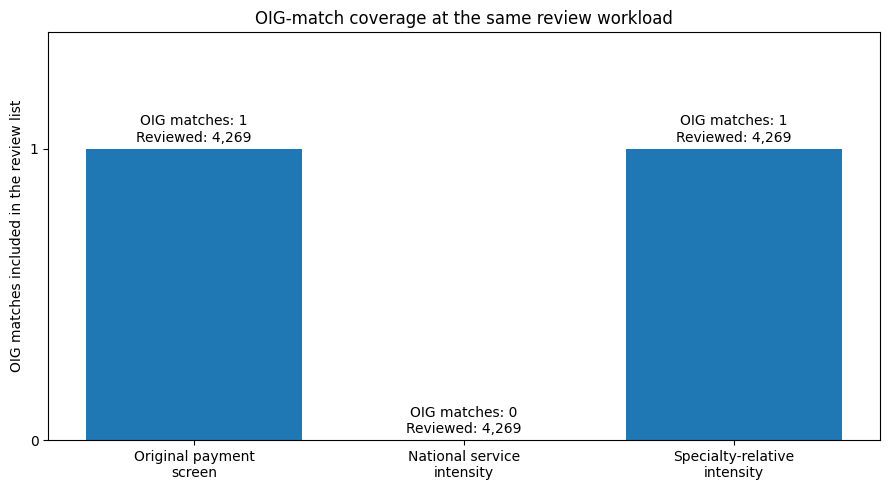

Eligible providers: 755020
Eligible OIG matches: 83
               screening_rule  reviewed_providers  oig_matches  oig_coverage_percent
     Original payment\nscreen                4269            1                   1.2
  National service\nintensity                4269            0                   0.0
Specialty-relative\nintensity                4269            1                   1.2


In [ ]:
# Chart 14: OIG-match coverage at the same review workload
chart14 = analysis_df.rename(columns={"Rndrng_NPI": "provider_id", "Rndrng_Prvdr_Type": "specialty",
    "Tot_Benes": "beneficiaries", "Tot_Mdcr_Pymt_Amt": "total_payment"}).copy()

chart14 = chart14[chart14["beneficiaries"] >= 100].copy()
chart14 = chart14[chart14["total_payment"] >= 0].copy()

# Calculate the original payment thresholds before restricting specialties.
total_payment_threshold14 = chart14["total_payment"].quantile(0.99)
payment_per_beneficiary_threshold14 = (chart14["payment_per_beneficiary"].quantile(0.99))

# Create the common population for all three rules.
chart14 = chart14[chart14["services_per_beneficiary"] > 0].copy()
chart14 = chart14.dropna(subset=["specialty"])
chart14 = chart14[chart14["specialty"] != ""].copy()

# Keep specialties with at least 100 eligible providers.
specialty_counts14 = chart14["specialty"].value_counts()
large_specialties14 = specialty_counts14[specialty_counts14 >= 100].index

chart14 = chart14[chart14["specialty"].isin(large_specialties14)].copy()

# Rule 1: Providers above BOTH payment thresholds.
high_total_payment14 = (chart14["total_payment"] >= total_payment_threshold14)
high_payment_per_beneficiary14 = (chart14["payment_per_beneficiary"] >= payment_per_beneficiary_threshold14)
payment_review14 = chart14[high_total_payment14 & high_payment_per_beneficiary14].copy()

# Every rule must review this same number of providers.
review_count14 = len(payment_review14)

# Rule 2: Highest service intensity nationally.
national_review14 = chart14.sort_values(["services_per_beneficiary", "provider_id"], ascending=[False, True])
national_review14 = national_review14.head(review_count14).copy()

# Rule 3: Calculate intensity percentile ranks within each specialty.
chart14["specialty_percentile"] = 0.0

for specialty14 in large_specialties14:
    specialty_rows14 = chart14["specialty"] == specialty14
    specialty_data14 = chart14[specialty_rows14]
    chart14.loc[specialty_rows14, "specialty_percentile"] = (specialty_data14["services_per_beneficiary"].rank(pct=True))

# Select the same number using the highest specialty percentile ranks.
specialty_review14 = chart14.sort_values(["specialty_percentile", "provider_id"],ascending=[False, True])
specialty_review14 = specialty_review14.head(review_count14).copy()

# Provider ID breaks ties.
# OIG status is not used to select providers.
summary14 = pd.DataFrame({"screening_rule":
    [   "Original payment\nscreen",
        "National service\nintensity",
        "Specialty-relative\nintensity"
    ], "reviewed_providers": [
        len(payment_review14),
        len(national_review14),
        len(specialty_review14)
    ], "oig_matches": [
        int(payment_review14["oig_matched"].sum()),
        int(national_review14["oig_matched"].sum()),
        int(specialty_review14["oig_matched"].sum())]})

# Calculate the percentage of eligible OIG matches covered.
total_oig_matches14 = int(chart14["oig_matched"].sum())

if total_oig_matches14 > 0:
    summary14["oig_coverage_percent"] = (summary14["oig_matches"] / total_oig_matches14 * 100).round(1)
else:
    summary14["oig_coverage_percent"] = None

# Create a label for each bar.
bar_labels14 = []

for match_count14 in summary14["oig_matches"]:
    bar_labels14.append(f"OIG matches: {match_count14}\nReviewed: {review_count14:,}")

# Create the chart.
plt.figure(figsize=(9, 5))

bars14 = plt.bar(summary14["screening_rule"],summary14["oig_matches"])
plt.bar_label(bars14, labels=bar_labels14, padding=3)

# Use whole-number tick marks because the chart counts providers.
largest_match_count14 = max(1, int(summary14["oig_matches"].max()))
tick_step14 = max(1, round(largest_match_count14 / 5))

plt.yticks(range(0, largest_match_count14 + 1, tick_step14))
plt.ylim(0, largest_match_count14 * 1.4)

plt.ylabel("OIG matches included in the review list")
plt.title("OIG-match coverage at the same review workload")
plt.tight_layout()
plt.show()

# Display the results.
print("Eligible providers:", len(chart14))
print("Eligible OIG matches:", total_oig_matches14)
print(summary14.to_string(index=False))

# This measures OIG-match coverage, not fraud-detection accuracy.

Finding: The common population contains 755,020 eligible providers, including 83 OIG matches. Each bar selects 4,269 providers for review. The original payment screen includes one OIG match, national service intensity screening includes none, and specialty intensity screening includes one. Since there is only one or zero matches per review list, there is not enough evidence to rank screening approaches.

### **Chart 15: Where Would the Specialty-Relative Screen Create Review Workload?**

Hypothesis: We expect flag rates to differ across locations because the mix of specialties and practice patterns varies between urban and rural areas.

Why It Matters: Differences in where flagged providers are located may affect how review work is distributed.Using flags per 1,000 providers, rather than raw counts, keeps large urban areas from dominating the comparison.

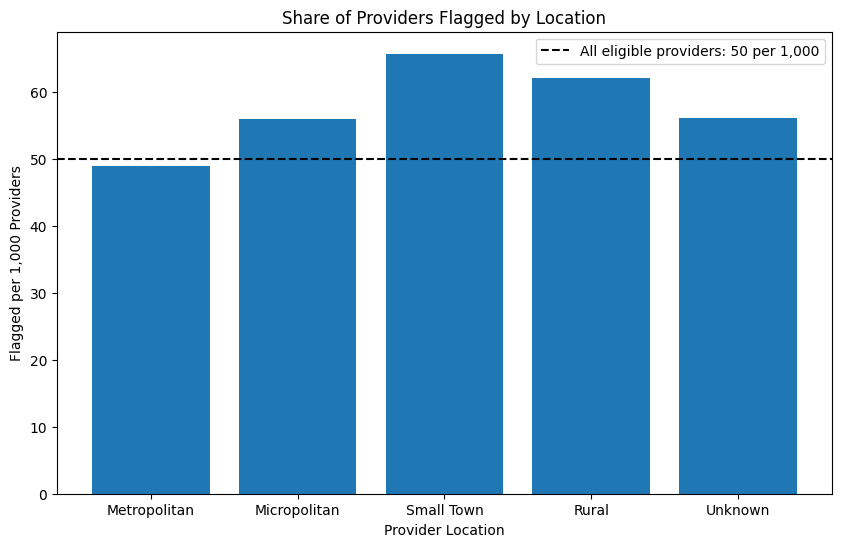

In [ ]:
threshold = 0.95 # I used the same percentile as Chart 12

# Keep providers with 100+ beneficiaries in specialties with at least 30 providers
chart_15 = payment_bene_df.dropna(subset=["services_per_beneficiary"]).copy()

specialty_counts = chart_15["Rndrng_Prvdr_Type"].value_counts()
large_specialties = specialty_counts[specialty_counts >= 30].index

chart_15 = chart_15[chart_15["Rndrng_Prvdr_Type"].isin(large_specialties)].copy()

# Flag providers whose services per patient are above their specialty's 95th percentile
cutoffs = chart_15.groupby("Rndrng_Prvdr_Type")["services_per_beneficiary"].quantile(threshold)
chart_15["cutoff"] = chart_15["Rndrng_Prvdr_Type"].map(cutoffs)
chart_15["flagged"] = chart_15["services_per_beneficiary"] > chart_15["cutoff"]

# Sort each provider into an urban or rural group based on its location description
chart_15["location"] = "Unknown"
ruca = chart_15["Rndrng_Prvdr_RUCA_Desc"]
chart_15.loc[ruca.str.startswith("Metropolitan", na=False), "location"] = "Metropolitan"
chart_15.loc[ruca.str.startswith("Micropolitan", na=False), "location"] = "Micropolitan"
chart_15.loc[ruca.str.startswith("Small town", na=False), "location"] = "Small Town"
chart_15.loc[ruca.str.startswith("Rural", na=False), "location"] = "Rural"

# Count how many providers are flagged out of every 1,000 in each location
summary_15 = chart_15.groupby("location").agg(eligible=("Rndrng_NPI", "count"),flagged=("flagged", "sum"))
summary_15["flags_per_1000"] = summary_15["flagged"] / summary_15["eligible"] * 1000
summary_15 = summary_15.loc[["Metropolitan", "Micropolitan", "Small Town", "Rural", "Unknown"]]

# Create Bar chart, adding a dashed line showing the overall flag rate
overall_rate = chart_15["flagged"].mean() * 1000
plt.figure(figsize=(10, 6))
plt.bar(summary_15.index, summary_15["flags_per_1000"])
plt.axhline(overall_rate, color="black", linestyle="--",label=f"All eligible providers: {overall_rate:.0f} per 1,000")

# Label the charts
plt.title("Share of Providers Flagged by Location")
plt.xlabel("Provider Location")
plt.ylabel("Flagged per 1,000 Providers")
plt.legend()
plt.show()

Finding: Metropolitan providers are the only group that was flagged below the overall average. All other location groups are above the average, with Small Town providers flagged most often, followed by Rural providers, while Micropolitan and Unknown providers was moderately above the average. The providers outside metropolitan areas are flagged more often relative to their numbers.In conclusion, the location of providers should not be used as an indicator of risk on its own, but it can be a useful factor for planning where review work will fall.

### **9. Conclusions:**

Overall, our analysis of 2024 Medicare Part B data revealed that federal spending is highly concentrated among a small percentage of providers, especially that high raw service volume and gross payments are primarily driven by practice size and clinical specialty rather than fraudulent behavior. When we compared CMS billing records against OIG exclusion lists, we found that purely financial screening thresholds overlook the majority of known bad actors, whereas behavioral indicators like unusually high services per beneficiary offer a stronger signal of abuse. Further, when we looked at geographic breakdowns, small towns experienced a disproportionately high rate of flagged providers per 1,000 residents.This suggests that rural regions may experience weaker regulatory oversight. Ultimately, These findings demonstrate that to effectively protect public healthcare funds, audit teams must pivot away from gross dollar amounts and instead prioritize normalized, specialty-adjusted behavioral metrics to identify true regulatory non-compliance.

### 9.2 Limitations

These are the limitations we found while working with CMS Medicare Part B and the OIG list of Excluded Individuals/Entities (LEIE):
*   The CMS data show annual provider totals, not individual claims. They cannot tell us whether a specific service was necessary, documented properly, or billed correctly.
*   ⁠An OIG exclusion match does not prove Medicare billing fraud. The exclusion dates and annual payment totals also cannot show whether a provider billed Medicare while excluded.
*   ⁠The charts use different filters, so their provider counts are not always directly comparable. Chart 10 includes providers with more than 100 beneficiaries and complete data for the measures shown.
*   ⁠Some matched-provider groups are small, so a few providers can have a noticeable effect on the results.
*   ⁠Specialty and patient-risk comparisons provide context, but they do not account for every difference in patients, services, or practice patterns.
*   ⁠This project is an initial screening analysis, not a tested model for predicting fraud. Future work could use individual claims and confirmed fraud cases to build and evaluate a model that flags potentially improper billing for further review.
*   ⁠Differences in geographic flag rates may reflect factors such as specialty mix or missing location data. They do not show that fraud or oversight differs by location.

### 9.3 Recommendations

Although raw billing numbers can look alarming, they don’t tell us much on their own, so these recommendations focus on fairer, more practical ways to spot possible problems in Medicare billing.

1.   **Screen providers by comparing them to their peers instead of relying on raw dollar or service totals:** CMS and OIG should stop treating high service counts or large payment totals as red flags by themselves, since these numbers mostly reflect big clinics or costly specialties. Screening should instead look at services per beneficiary, compared against providers in the same specialty and adjusted for patient age and risk. Pre-payment reviews of the top 10% of billers can help protect the largest share of taxpayer funds, while weaker signals like procedure-code variety should only add context.
2.   **Treat flags as leads to investigate and assign audit staff based on regional flag rates:** A flag or an OIG match does not prove fraud, so audit teams should treat these results as a starting point for a closer look. Reviewers should check claim timelines against exact OIG exclusion dates, reinstatement records, and the legal reasons for exclusion. When planning audit capacity, CMS should assign staff based on regional flag rates instead of provider headcounts, so small towns and non-metropolitan areas with higher flag rates get the oversight they need.

Overall, these recommendations show the value of comparing providers fairly, confirming findings before drawing conclusions, and sharing audit resources where they are needed most.


### **References:**

1) https://app.datacamp.com/learn/assignments - Datacamp modules
2) https://github.com/soltaniehha/Intro-to-Data-Analytics - BA780 colab notebooks, Fall 2026, Mohammed Soltanieh-ha
3) https://oig.hhs.gov/exclusions/ - OIG exclusion information
4) https://www.geeksforgeeks.org/data-analysis/data-cleaning-introduction/ - Geeks for Geeks, Data Cleaning Basics
5) https://github.com/soltaniehha/Intro-to-Data-Analytics/tree/main/docs/team-projects - Previous Years Projects
6) https://github.com/soltaniehha/Intro-to-Data-Analytics/blob/main/docs/team-projects/2025/A06-Impact-of-Crime-%26-Unemployment-in-LA.ipynb - BA780 colab notebooks, Fall 2026, Mohammed Soltanieh-ha; Group A06 Impact of Crime Unemployment in LA


**AI Disclaimer:** Our team used ChatGPT, Google Gemini, Claude, Cursor, and Grammarly to support data cleaning, exploratory analysis, visualization, and writing. We used ChatGPT, Claude, and Cursor to generate Python/Pandas syntax, debug code, resolve errors, and improve chart types, labels, and readability. Google Gemini helped us review our cleaning and merging procedures, while ChatGPT supported the creation of the data dictionary and cleaning summary table. We also used ChatGPT and Claude to brainstorm and refine exploratory questions about Medicare billing patterns. Each team member independently developed five charts, producing 25 charts in total. We then used AI to help compare the questions and visualizations before discussing and selecting the five that allowed us to tell the most effective story. ChatGPT also helped us check whether our written interpretations matched the displayed results, and Grammarly helped refine grammar and wording. All AI-assisted code and text were reviewed and verified by the team, and all code was tested against the data by running the notebook from top to bottom. AI supported our process but was not used to generate our conclusions.

**For the Second part of the project**

**Ahan** - Used GPT 6.1 Sol to help design workbook flow. I used it to help create a more effective storyline so the visualization order makes sense and showcases our thought process. I also used it to help whittle down my questions into more specific ideas that can be tested. One instance of this was the idea to compare providers with high payment levels to those with high service intensity and compare the overlap. Additionally, I used it to help me debug and suggest implementation. All code generated by AI was reviewed and edited by me to ensure that it worked correctly. The notebook was run top to bottom after clearing previous outputs and variables to make sure of this. I also used it as an explanatory tool to help me understand my teammates' code easily. As a team, we used AI to help us find the most efficient way to divide workload and ensure that everyone had an equal amount of contribution and input to our final workbook. My work was on charts 11, 13, and 14

**Yuxin** - For the second half of this project (when we need to create more charts), I asked ChatGPT to help me brainstorm ideas that can help us tell a better story of our dataset. Then, after each of us came up with some ideas, I shared our suggestions and my thoughts with ChatGPT and Claude and asked them to help us select 15 charts that best fit our dataset and project goals. In the notebook,  I used ChatGPT and Claude to revise the data dictionary descriptions for the CMS and LEIE fields like checking that they matched the variables and cleaning steps in our notebook. For Charts 3, 4 and 12, I used it to debug the code and rewrite some part of the code for better visualization. Also, I use it to narrow down my key finding and recommendations into short paragraphs after the charts. Besides, I use ChatGPT to help me go through my teammates’ code and charts to have a better and clear understanding of the whole project.

**Alice** -  For AI tools, I used Claude Opus5.5 to brainstorm ideas for the final charts to try to make our ideas into a whole story and with clear chapters, improve the visualizations for Charts 8, 9, and 15, and give me suggestions for the code when I was unsure how to implement a step. Claude also helped me to debug errors, explained each step of the code, narrowed down my conclusions and  discription for each charts with more precise wordings. It also helped me understand my teammates’ charts and code and go through the whole notebook more easily, and refined the wording and grammar of my written sections. I personally tested all of the code and made sure I understood how it works before including it in the notebook, and made sure every description is based on my own idea and thoughts.

**Ujjwala** - After our team organized the visualization flow, I used ChatGPT to understand how my teammates’ code and charts related to my assigned charts: 6, 7, and 10. For my charts, ChatGPT suggested Python code and helped troubleshoot coding issues. I used the code and chart outputs to write my explanations. I ran and tested the code, reviewed the outputs, and revised the code and explanations as needed. The final choices about the analysis and its interpretation were mine.

**Sree** - In completing this project, I used Google Gemini PRO to support in technical and written areas. Specifically, I was responsible for creating and finalizing Charts 1, 2, and 5. Once I drafted the code for these charts, I used AI to improve the efficiency of my Python code and to verify that the plots accurately displayed the underlying data. Additionally, I used Gemini to review my teammates’ contributions, allowing me to better understand their code and visuals. Finally, I used the model to refine my respective written responses, helping elevate the clarity and professionalism of the chart findings.